# DeliveryRisk AI

Sistema preditivo para identificação de riscos de atraso em entregas do e-commerce brasileiro, utilizando técnicas de Machine Learning com o dataset Brazilian E-Commerce Public Dataset by Olist.

## Fase 1 — Carregamento, Limpeza e Análise Exploratória dos Dados (EDA)

Nesta etapa será realizado o carregamento e o diagnóstico inicial dos cinco arquivos CSV do dataset Olist, buscando compreender sua estrutura, qualidade e características antes da integração dos dados e da preparação para o treinamento dos modelos de Machine Learning.

Serão executadas as seguintes ações:

- Carregamento dos cinco arquivos CSV: pedidos, itens dos pedidos, clientes, produtos e vendedores;
- Verificação das dimensões, quantidade de registros e número de colunas de cada dataset;
- Identificação dos tipos de dados e análise da estrutura das variáveis;
- Verificação da presença de valores ausentes e análise de sua distribuição;
- Identificação de registros duplicados e possíveis inconsistências nos dados;
- Análise das chaves identificadoras, integridade dos registros e relacionamentos entre os datasets;
- Investigação de valores extremos (*outliers*) em variáveis numéricas;
- Análise das distribuições das variáveis numéricas e categóricas;
- Investigação de padrões temporais e possíveis anomalias nos dados;
- Geração e armazenamento de gráficos e visualizações utilizados na análise exploratória;
- Documentação dos problemas de qualidade identificados e das decisões necessárias para as próximas etapas do pipeline.


In [81]:
# Bibliotecas do projeto.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
)

In [1]:
# Importação das funções do projeto.

import sys
import importlib
from pathlib import Path

raiz_projeto = Path.cwd().parent.parent
sys.path.insert(0, str(raiz_projeto))

# Importação dos módulos.
import pipeline.src.analise_exploratoria
import pipeline.src.tratamento
import pipeline.src.integracao_dados
import pipeline.src.feature_engineering
import pipeline.src.preparacao_modelo
import pipeline.src.modelos

# Recarregamento dos módulos.
importlib.reload(pipeline.src.analise_exploratoria)
importlib.reload(pipeline.src.integracao_dados)
importlib.reload(pipeline.src.feature_engineering)
importlib.reload(pipeline.src.preparacao_modelo)
importlib.reload(pipeline.src.modelos)

# Importação das funções por modulo.
from pipeline.src.carregamento import (
    carregar_dataset,
    carregar_datasets,
)

from pipeline.src.analise_exploratoria import (
    resumir_datasets,
    inspecionar_dados,
    analisar_valores_ausentes,
    analisar_ausencias_por_categoria,
    inspecionar_ausencias_por_status,
    inspecionar_registros_com_ausencias,
    analisar_duplicatas,
    analisar_chaves,
    analisar_chave_composta,
    grafico_valores_ausentes,
    grafico_distribuicao_numericas,
    grafico_distribuicao_categoricas,
    grafico_correlacao,
)

from pipeline.src.tratamento import (
    validar_colunas,
    converter_colunas_para_data,
    normalizar_texto,
    validar_chaves,
    validar_valores_numericos,
    resumir_qualidade_dados,
)

from pipeline.src.integracao_dados import (
    construir_base_integrada,
    investigar_pedidos_sem_itens,
)

from pipeline.src.feature_engineering import (
    definir_features,
    criar_atributos_temporais,
    separar_tipos_features,
    criar_pipeline_preprocessamento,
    validar_features,
    filtrar_pedidos_elegiveis,
)

from pipeline.src.preparacao_modelo import (
    dividir_dados_temporalmente,
    validar_divisao_temporal,
)

from pipeline.src.modelos import (
    definir_configuracoes_modelos,
    executar_experimentos,
    registrar_resultados,
)


In [3]:

# Carregamento dos datasets.

caminho_dados = raiz_projeto / "data" / "raw"

datasets = carregar_datasets(caminho_dados)


Carregando dataset: olist_orders_dataset.csv
Dataset 'orders' carregado com sucesso: 99441 linhas e 8 colunas.
Carregando dataset: olist_order_items_dataset.csv
Dataset 'order_items' carregado com sucesso: 112650 linhas e 7 colunas.
Carregando dataset: olist_customers_dataset.csv
Dataset 'customers' carregado com sucesso: 99441 linhas e 5 colunas.
Carregando dataset: olist_products_dataset.csv
Dataset 'products' carregado com sucesso: 32951 linhas e 9 colunas.
Carregando dataset: olist_sellers_dataset.csv
Dataset 'sellers' carregado com sucesso: 3095 linhas e 4 colunas.

Todos os datasets foram carregados com sucesso!


### Análise Exploratória dos Dados (EDA)

Com os cinco datasets carregados, esta etapa tem como objetivo investigar sua estrutura, qualidade e características gerais, identificando possíveis problemas que possam influenciar as próximas etapas do pipeline.

Inicialmente, serão realizadas inspeções e análises diagnósticas, seguidas da exploração das distribuições das variáveis e da geração de visualizações. Os resultados obtidos servirão de base para documentar os achados e orientar as decisões de limpeza, tratamento e preparação dos dados.

In [4]:
resumir_datasets(datasets)

,dataset,linhas,colunas,valores_ausentes,registros_duplicados
0,orders,99441,8,4908,0
1,order_items,112650,7,0,0
2,customers,99441,5,0,0
3,products,32951,9,2448,0
4,sellers,3095,4,0,0


### Análise inicial dos Dados

In [5]:
inspecionar_dados(datasets["order_items"], "order_items")


========================= Inspeção: order_items =========================

Dimensões do dataset:
Linhas: 112650
Colunas: 7

Colunas:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Tipos de dados:
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 no

In [6]:
inspecionar_dados(datasets["customers"], "customers")


========================= Inspeção: customers =========================

Dimensões do dataset:
Linhas: 99441
Colunas: 5

Colunas:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Tipos de dados:
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB

Estatísticas descritivas:
    

In [7]:
inspecionar_dados(datasets["products"], "products")


========================= Inspeção: products =========================

Dimensões do dataset:
Linhas: 32951
Colunas: 9

Colunas:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Tipos de dados:
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   produc

In [8]:
inspecionar_dados(datasets["sellers"], "sellers")


========================= Inspeção: sellers =========================

Dimensões do dataset:
Linhas: 3095
Colunas: 4

Colunas:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Tipos de dados:
seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str
dtype: object

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 230.3 KB

Estatísticas descritivas:
                         count unique                               top  freq  \
seller_id                 3095   3095  3442f8959a84dea7ee197c632

In [9]:
inspecionar_dados(datasets["orders"], "orders")


========================= Inspeção: orders =========================

Dimensões do dataset:
Linhas: 99441
Colunas: 8

Colunas:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Tipos de dados:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2  

### Análise de valores ausentes

In [10]:
analisar_valores_ausentes(datasets["orders"], "orders")

,quantidade_ausentes,percentual_ausentes
order_delivered_customer_date,2965,2.981668
order_delivered_carrier_date,1783,1.793023
order_approved_at,160,0.160899
order_id,0,0.000000
customer_id,0,0.000000
order_status,0,0.000000
order_purchase_timestamp,0,0.000000
order_estimated_delivery_date,0,0.000000


### Análise dos valores ausentes em `orders`

O dataset `orders` possui 99.441 registros e 8 colunas. A inspeção identificou valores ausentes em três campos relacionados ao processamento e à entrega dos pedidos.

| Coluna | Valores ausentes | Percentual |
|---|---:|---:|
| `order_approved_at` | 160 | 0,16% |
| `order_delivered_carrier_date` | 1.783 | 1,79% |
| `order_delivered_customer_date` | 2.965 | 2,98% |

As demais colunas não apresentam valores ausentes. O campo `order_delivered_customer_date` concentra a maior quantidade de ausências, seguido de `order_delivered_carrier_date` e `order_approved_at`.

A presença de valores ausentes nesses campos deve ser analisada considerando o status de cada pedido, pois nem todos os pedidos necessariamente percorrem todas as etapas do processo de entrega. Por exemplo, pedidos cancelados ou indisponíveis podem não possuir datas de entrega.

A inspeção também identificou que todas as colunas estão armazenadas como texto, inclusive as datas. A conversão dos campos temporais e as decisões sobre tratamento dos valores ausentes serão avaliadas nas etapas posteriores, conforme as necessidades da preparação dos dados.


In [11]:
analisar_valores_ausentes(datasets["order_items"], "order_items")

,quantidade_ausentes,percentual_ausentes
order_id,0,0.0
order_item_id,0,0.0
product_id,0,0.0
seller_id,0,0.0
shipping_limit_date,0,0.0
price,0,0.0
freight_value,0,0.0


In [12]:
analisar_valores_ausentes(datasets["customers"], "customers")

,quantidade_ausentes,percentual_ausentes
customer_id,0,0.0
customer_unique_id,0,0.0
customer_zip_code_prefix,0,0.0
customer_city,0,0.0
customer_state,0,0.0


In [13]:
analisar_valores_ausentes(datasets["products"], "products")

,quantidade_ausentes,percentual_ausentes
product_category_name,610,1.851234
product_name_lenght,610,1.851234
product_description_lenght,610,1.851234
product_photos_qty,610,1.851234
product_weight_g,2,0.006070
product_length_cm,2,0.006070
product_height_cm,2,0.006070
product_width_cm,2,0.006070
product_id,0,0.000000


In [14]:
analisar_valores_ausentes(datasets["sellers"], "sellers")

,quantidade_ausentes,percentual_ausentes
seller_id,0,0.0
seller_zip_code_prefix,0,0.0
seller_city,0,0.0
seller_state,0,0.0


Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\valores_ausentes.png


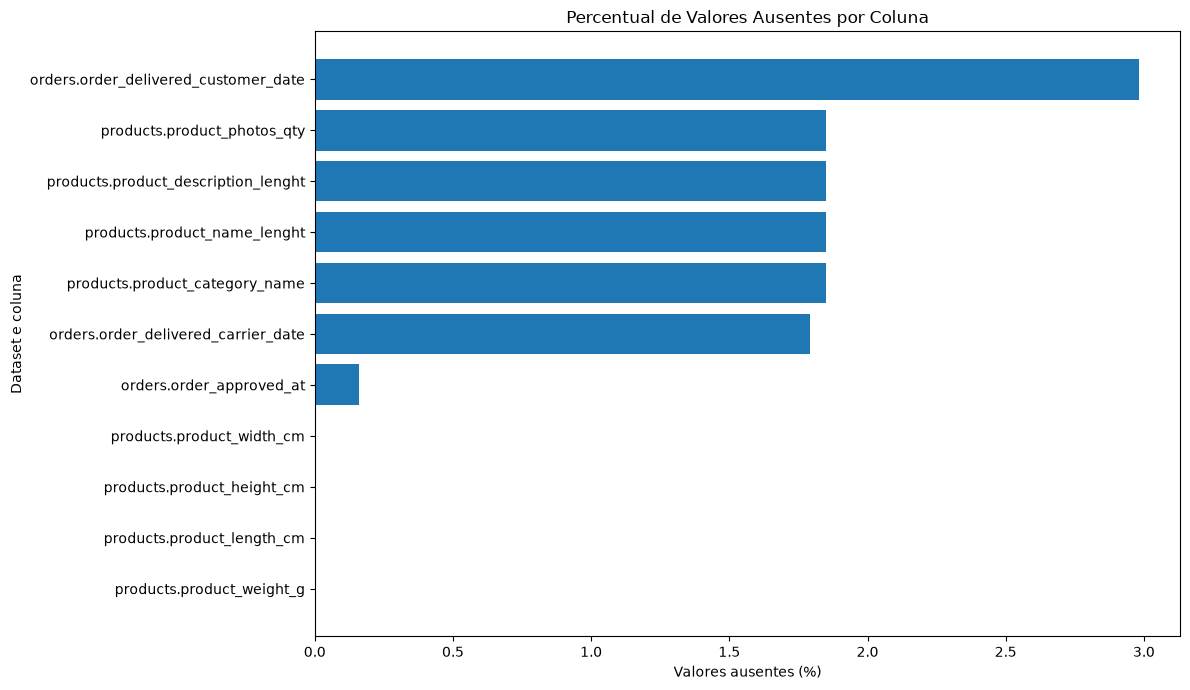

In [15]:
grafico_valores_ausentes(datasets)

### **Visualização do percentual de valores ausentes**


A visualização destacou as seguintes ocorrências:

- **`orders.order_delivered_customer_date`**: aproximadamente 2,98% de valores ausentes.
- **`orders.order_delivered_carrier_date`**: aproximadamente 1,78% de valores ausentes.
- **`orders.order_approved_at`**: aproximadamente 0,16% de valores ausentes.
- **Dataset `products`**: aproximadamente 1,85% de valores ausentes nas colunas `product_photos_qty`, `product_description_lenght`, `product_name_lenght` e `product_category_name`.

As colunas de dimensões e peso dos produtos também apresentaram valores ausentes, mas em percentuais muito baixos.

O gráfico complementa a análise tabular de valores ausentes realizada anteriormente, facilitando a comparação entre as colunas e a identificação das variáveis que exigem maior atenção nas etapas posteriores.



In [16]:
colunas_datas = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
]

resultados_ausencias = analisar_ausencias_por_categoria(
    df=datasets["orders"],
    colunas=colunas_datas,
    categoria="order_status",
)

for coluna, resultado in resultados_ausencias.items():
    print(f"Ausências em {coluna}")
    display(resultado)

Ausências em order_approved_at


,quantidade_ausentes,total_registros,percentual_ausentes
order_status,,,
canceled,141,625,22.560000
delivered,14,96478,0.014511
created,5,5,100.000000
approved,0,2,0.000000
invoiced,0,314,0.000000
processing,0,301,0.000000
shipped,0,1107,0.000000
unavailable,0,609,0.000000


Ausências em order_delivered_carrier_date


,quantidade_ausentes,total_registros,percentual_ausentes
order_status,,,
unavailable,609,609,100.000000
canceled,550,625,88.000000
invoiced,314,314,100.000000
processing,301,301,100.000000
created,5,5,100.000000
approved,2,2,100.000000
delivered,2,96478,0.002073
shipped,0,1107,0.000000


Ausências em order_delivered_customer_date


,quantidade_ausentes,total_registros,percentual_ausentes
order_status,,,
shipped,1107,1107,100.000000
canceled,619,625,99.040000
unavailable,609,609,100.000000
invoiced,314,314,100.000000
processing,301,301,100.000000
delivered,8,96478,0.008292
created,5,5,100.000000
approved,2,2,100.000000


In [17]:
pedidos_delivered_com_ausencias = inspecionar_ausencias_por_status(
    df=datasets["orders"],
    status="delivered",
    colunas=[
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
    ],
    colunas_adicionais=["order_purchase_timestamp"],
)

display(pedidos_delivered_com_ausencias)

,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN
5323,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33
16567,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06
19031,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38
20618,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN
22663,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47
23156,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19
26800,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01
38290,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58
39334,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23


### Investigação de pedidos `delivered` com datas ausentes

A inspeção dos pedidos com status `delivered` identificou **23 registros com pelo menos uma data ausente** entre as variáveis analisadas.

Foram encontradas as seguintes ausências:

- `order_approved_at`: 14 registros;
- `order_delivered_carrier_date`: 2 registros;
- `order_delivered_customer_date`: 8 registros.

A soma resulta em 24 ocorrências de ausência, pois um dos pedidos apresenta valores ausentes simultaneamente em `order_delivered_carrier_date` e `order_delivered_customer_date`. Portanto, são 23 pedidos distintos.

Os 14 pedidos sem data de aprovação concentram-se em registros de janeiro e fevereiro de 2017, embora apresentem datas posteriores de envio à transportadora e de entrega ao cliente. Também foram encontrados dois pedidos sem data de entrega à transportadora, sendo que um deles apresenta a data de entrega ao cliente preenchida. Por fim, oito pedidos não possuem data de entrega ao cliente, incluindo registros de novembro de 2017 e junho e julho de 2018.

A ausência dessas datas em pedidos classificados como `delivered` representa uma inconsistência aparente que merece investigação nas etapas posteriores. Contudo, os dados disponíveis não permitem determinar a causa dessas ocorrências.


In [18]:
colunas_produtos = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

produtos_com_ausencias = inspecionar_registros_com_ausencias(
    df=datasets["products"],
    colunas=colunas_produtos,
    coluna_id="product_id",
)

print("Total de produtos com pelo menos uma ausência:",
      len(produtos_com_ausencias))

display(produtos_com_ausencias.head(15))

Total de produtos com pelo menos uma ausência: 611


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [19]:
colunas_produtos = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

resumo_padroes = (
    produtos_com_ausencias[colunas_produtos]
    .isna()
    .value_counts()
    .rename("quantidade_registros")
    .reset_index()
)

display(resumo_padroes)

,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,quantidade_registros
0,True,True,True,True,False,False,False,False,609
1,False,False,False,False,True,True,True,True,1
2,True,True,True,True,True,True,True,True,1


In [20]:


colunas_fisicas = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

mascara_fisicos_ausentes = datasets["products"][colunas_fisicas].isna().any(axis=1)

produtos_fisicos_ausentes = datasets["products"].loc[
    mascara_fisicos_ausentes
]

display(produtos_fisicos_ausentes)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Análise de valores ausentes — dataset `products`

A investigação identificou **611 produtos com pelo menos um valor ausente**, distribuídos em três padrões:

- **609 produtos:** apresentam valores ausentes simultaneamente nas colunas `product_category_name`, `product_name_lenght`, `product_description_lenght` e `product_photos_qty`, enquanto o peso e as dimensões estão preenchidos.
- **1 produto:** apresenta valores ausentes nas quatro colunas físicas: `product_weight_g`, `product_length_cm`, `product_height_cm` e `product_width_cm`.
- **1 produto:** apresenta valores ausentes em todas as oito colunas descritivas e físicas, exceto `product_id`.

O padrão predominante indica que as ausências nas informações descritivas ocorrem conjuntamente. Entretanto, essa observação, por si só, não permite determinar a causa das ausências.

#### Investigação das ausências em peso e dimensões

A inspeção dos registros com valores ausentes nas variáveis físicas identificou dois produtos:

- **Produto `09ff539a621711667c43eba6a3bd8466`:** possui categoria e informações descritivas preenchidas, mas não apresenta valores de peso ou dimensões.
- **Produto `5eb564652db742ff8f28759cd8d2652a`:** apresenta apenas o identificador preenchido; as demais informações estão ausentes.

Esses casos merecem atenção porque peso e dimensões podem ser relevantes para análises logísticas e para variáveis relacionadas ao risco de atraso.


### Analise de duplicadas

In [21]:
for nome, df in datasets.items():
    print(f"\nDataset: {nome}")
    display(analisar_duplicatas(df, nome))


Dataset: orders

Análise de duplicatas: orders
Registros duplicados: 0
Percentual de duplicatas: 0.00%


0


Dataset: order_items

Análise de duplicatas: order_items
Registros duplicados: 0
Percentual de duplicatas: 0.00%


0


Dataset: customers

Análise de duplicatas: customers
Registros duplicados: 0
Percentual de duplicatas: 0.00%


0


Dataset: products

Análise de duplicatas: products
Registros duplicados: 0
Percentual de duplicatas: 0.00%


0


Dataset: sellers

Análise de duplicatas: sellers
Registros duplicados: 0
Percentual de duplicatas: 0.00%


0

### Análise de duplicatas

A análise de duplicatas foi realizada nos cinco datasets: `orders`, `order_items`, `customers`, `products` e `sellers`.

Os resultados indicaram **zero linhas completamente duplicadas** em todos os datasets, correspondendo a um percentual de duplicatas completas de 0%.

Esse resultado demonstra que não foram encontradas linhas com todos os valores repetidos. Entretanto, a ausência de duplicatas completas não garante a unicidade dos identificadores nem a integridade dos relacionamentos entre os datasets.

**Conclusão:** não foram identificadas duplicatas completas que demandem tratamento nesta etapa.

### Analise de chaves

In [22]:
analisar_chaves(datasets["order_items"], "order_items", "order_id")


Análise da coluna identificadora: order_items.order_id
Valores ausentes: 0
Valores duplicados: 13984
Valores únicos: 98666


{'dataset': 'order_items',
 'coluna': 'order_id',
 'valores_ausentes': 0,
 'valores_duplicados': 13984,
 'valores_unicos': 98666}

In [23]:
analisar_chaves(datasets["orders"], "orders", "order_id")


Análise da coluna identificadora: orders.order_id
Valores ausentes: 0
Valores duplicados: 0
Valores únicos: 99441


{'dataset': 'orders',
 'coluna': 'order_id',
 'valores_ausentes': 0,
 'valores_duplicados': 0,
 'valores_unicos': 99441}

In [24]:
analisar_chaves(datasets["customers"], "customers", "customer_id")


Análise da coluna identificadora: customers.customer_id
Valores ausentes: 0
Valores duplicados: 0
Valores únicos: 99441


{'dataset': 'customers',
 'coluna': 'customer_id',
 'valores_ausentes': 0,
 'valores_duplicados': 0,
 'valores_unicos': 99441}

In [25]:
analisar_chaves(datasets["products"], "products", "product_id")


Análise da coluna identificadora: products.product_id
Valores ausentes: 0
Valores duplicados: 0
Valores únicos: 32951


{'dataset': 'products',
 'coluna': 'product_id',
 'valores_ausentes': 0,
 'valores_duplicados': 0,
 'valores_unicos': 32951}

In [26]:
analisar_chaves(datasets["sellers"], "sellers", "seller_id")


Análise da coluna identificadora: sellers.seller_id
Valores ausentes: 0
Valores duplicados: 0
Valores únicos: 3095


{'dataset': 'sellers',
 'coluna': 'seller_id',
 'valores_ausentes': 0,
 'valores_duplicados': 0,
 'valores_unicos': 3095}

### **Análise de unicidade das chaves**

A análise das colunas identificadoras avaliou a presença de valores ausentes, a repetição de identificadores e a quantidade de valores distintos nos datasets.

Nos datasets `orders`, `customers`, `products` e `sellers`, as colunas identificadoras analisadas não apresentaram valores ausentes ou repetidos. Foram identificados:

- `orders.order_id`: 99.441 valores únicos;
- `customers.customer_id`: 99.441 valores únicos;
- `products.product_id`: 32.951 valores únicos;
- `sellers.seller_id`: 3.095 valores únicos.

No dataset `order_items`, a coluna `order_id` apresentou 98.666 valores distintos e 13.984 ocorrências repetidas, sem valores ausentes. Esse comportamento é esperado, pois um pedido pode conter vários itens. Portanto, `order_id`, isoladamente, não identifica unicamente cada registro desse dataset.

A análise de `orders.order_id` confirmou a existência de 99.441 identificadores únicos para 99.441 registros, sem valores ausentes ou duplicados. Esse resultado indica que a coluna pode ser utilizada para identificar individualmente os pedidos e relacioná-los aos demais datasets.

In [27]:
resultado_chave_composta = analisar_chave_composta(
    df=datasets["order_items"],
    nome="order_items",
    colunas=["order_id", "order_item_id"],
)

Análise da chave composta: order_items.order_id, order_item_id
Registros com valores ausentes na chave: 0
Combinações duplicadas: 0
Combinações únicas: 112650
Total de registros: 112650


#### **Análise da chave composta — dataset `order_items`**

Para verificar a unicidade dos registros de itens dos pedidos, foi analisada a combinação das colunas `order_id` e `order_item_id`.

A análise identificou zero registros com valores ausentes nos componentes da chave composta e zero combinações duplicadas. As 112.650 combinações únicas correspondem ao total de 112.650 registros do dataset.

O resultado confirma que a combinação `order_id` + `order_item_id` identifica unicamente cada item de pedido. Já a coluna `order_id`, isoladamente, pode apresentar valores repetidos, pois um mesmo pedido pode conter múltiplos itens.

### Análise de distribuição de variáveis númericas

Nenhuma variável numérica encontrada em 'orders'.
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_numericas_order_items.png


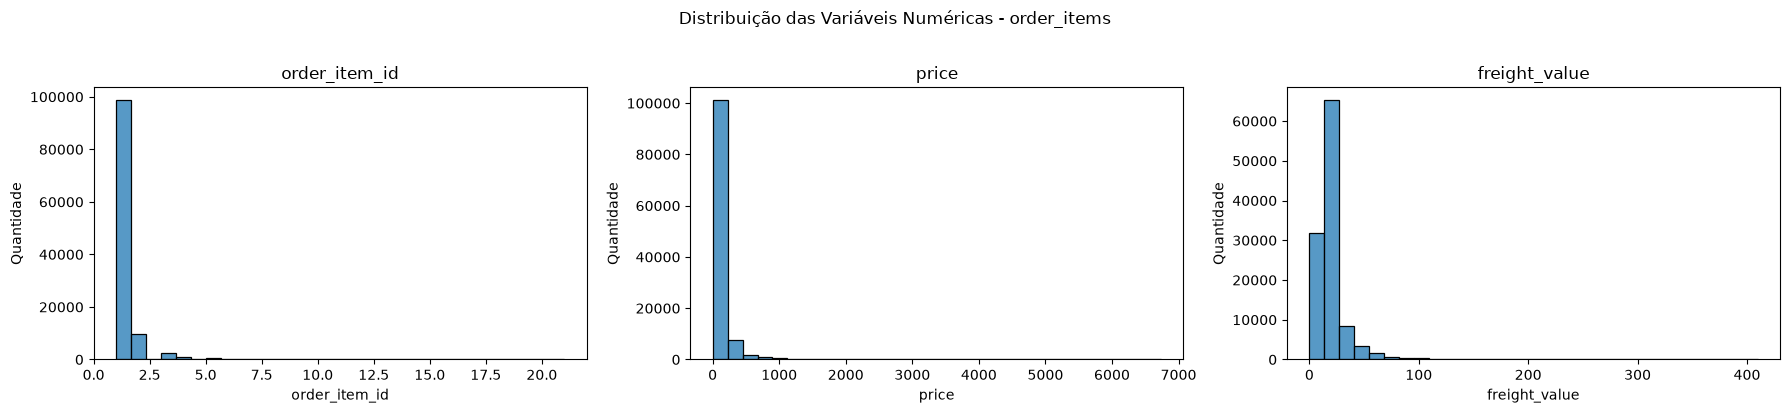

Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_numericas_customers.png


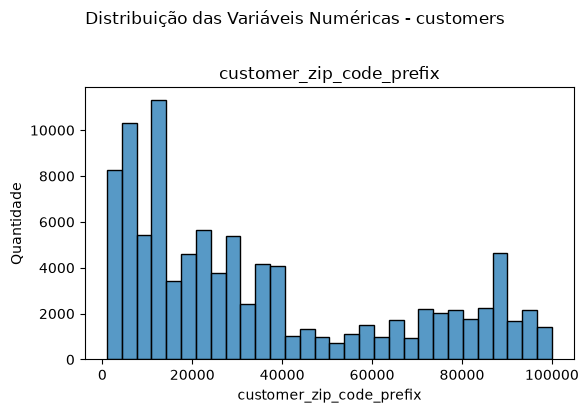

Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_numericas_products.png


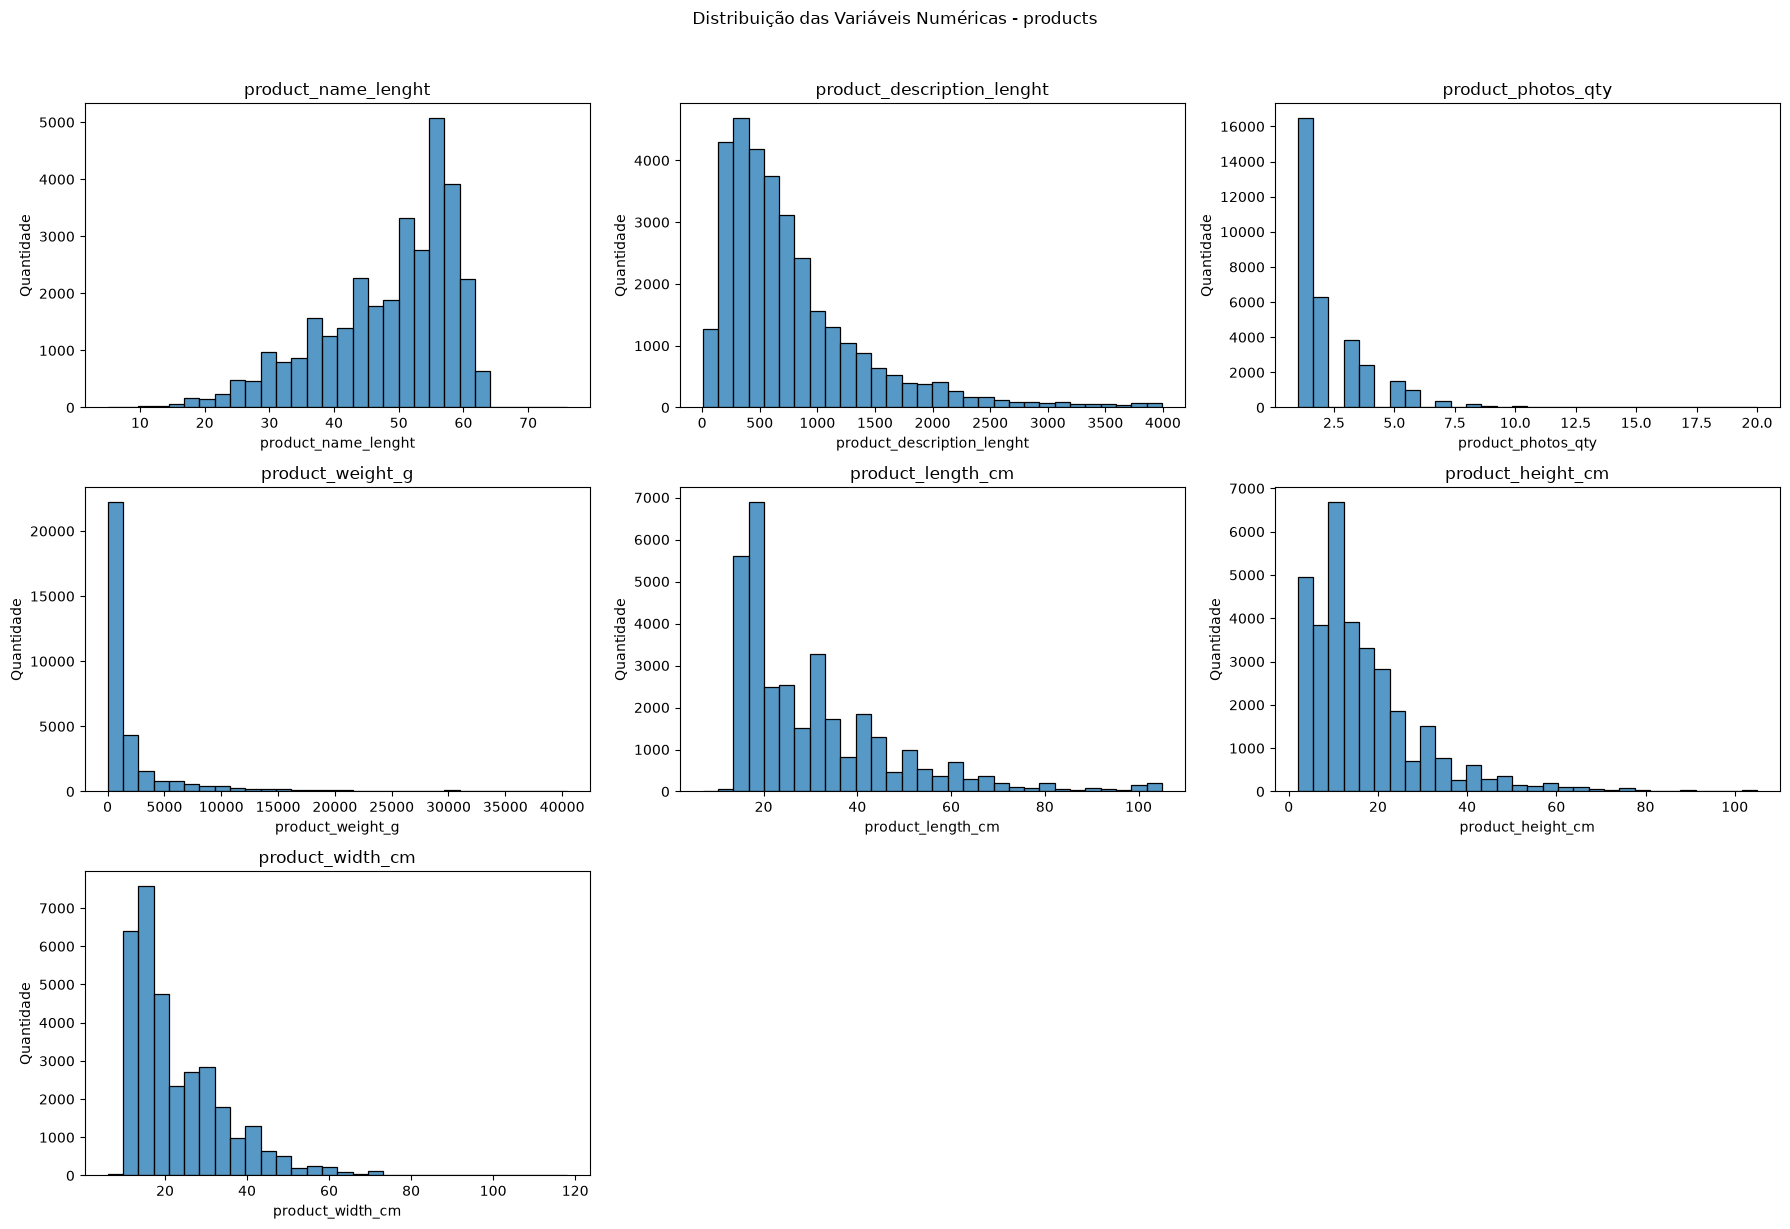

Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_numericas_sellers.png


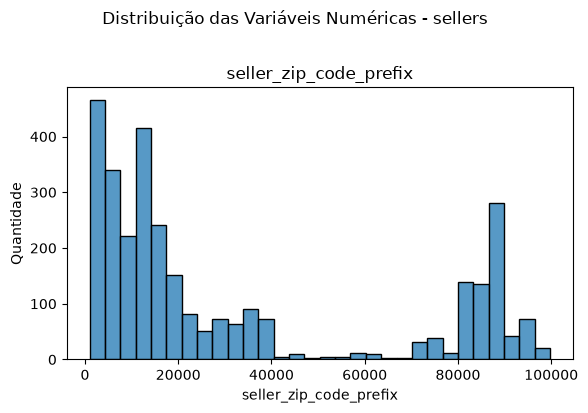

In [28]:
for nome, df in datasets.items():
    grafico_distribuicao_numericas(df, nome=nome)

### Análise das distribuições das variáveis numéricas

A análise visual dos histogramas dos datasets `order_items`, `customers`, `products` e `sellers` permitiu observar padrões de concentração, assimetria e possíveis valores extremos. As interpretações apresentadas são exploratórias e se limitam aos padrões visuais identificados nos gráficos.

#### Dataset `order_items`

As variáveis `price` e `freight_value` apresentam distribuições assimétricas à direita, com maior concentração de registros em faixas de valores menores e caudas que se estendem para valores mais elevados. Esses padrões indicam que os valores estão distribuídos de maneira desigual, com algumas observações relativamente altas.

A variável `order_item_id` apresenta maior concentração nos primeiros valores inteiros. Como representa a posição sequencial do item dentro de um pedido, sua distribuição está relacionada à estrutura dos pedidos. Entretanto, a quantidade de itens por pedido deve ser avaliada considerando os registros agrupados por `order_id`, e não apenas pelo histograma dessa variável.

#### Dataset `customers`

A variável `customer_zip_code_prefix` apresenta concentrações distintas ao longo da faixa de valores observada. Como representa um código postal, não uma medida quantitativa contínua, seu histograma deve ser interpretado com cautela. Uma análise geográfica mais detalhada poderá considerar as informações de cidade e estado em etapas posteriores.

#### Dataset `products`

As variáveis `product_description_lenght`, `product_photos_qty`, `product_weight_g` e as dimensões físicas apresentam concentrações em determinadas faixas de valores, com distribuições que se estendem para valores maiores.

A variável `product_name_lenght` apresenta concentração em uma faixa relativamente estreita, com aparente redução de frequência nos valores mais altos. A existência de um possível limite para o comprimento dos nomes não pode ser confirmada apenas pela inspeção visual do histograma.

Essas distribuições ajudam a caracterizar as variáveis relacionadas às descrições e às características físicas dos produtos. Os gráficos, isoladamente, não permitem determinar se eventuais valores extremos são erros ou observações válidas.

#### Dataset `sellers`

A variável `seller_zip_code_prefix` apresenta concentrações distintas ao longo da faixa de valores observada. Assim como em `customers`, trata-se de um código postal, e não de uma medida quantitativa contínua. Sua distribuição pode contribuir para uma investigação geográfica posterior, em conjunto com as informações de localização dos clientes.

#### Síntese dos achados

Os histogramas permitem observar diferentes padrões de distribuição entre as variáveis analisadas. Em particular, `price` e `freight_value` apresentam assimetria à direita, enquanto as variáveis de produtos exibem concentrações em determinadas faixas de valores.

Esses resultados contribuem para a compreensão inicial dos dados e ajudam a orientar análises posteriores, caso sejam necessárias. Nenhuma variável foi transformada, nenhum registro foi excluído e nenhum valor foi classificado como erro exclusivamente com base nos histogramas.

### Análise de distribuição de variáveis categóricas


Distribuição das variáveis categóricas: orders
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_categoricas_orders.png


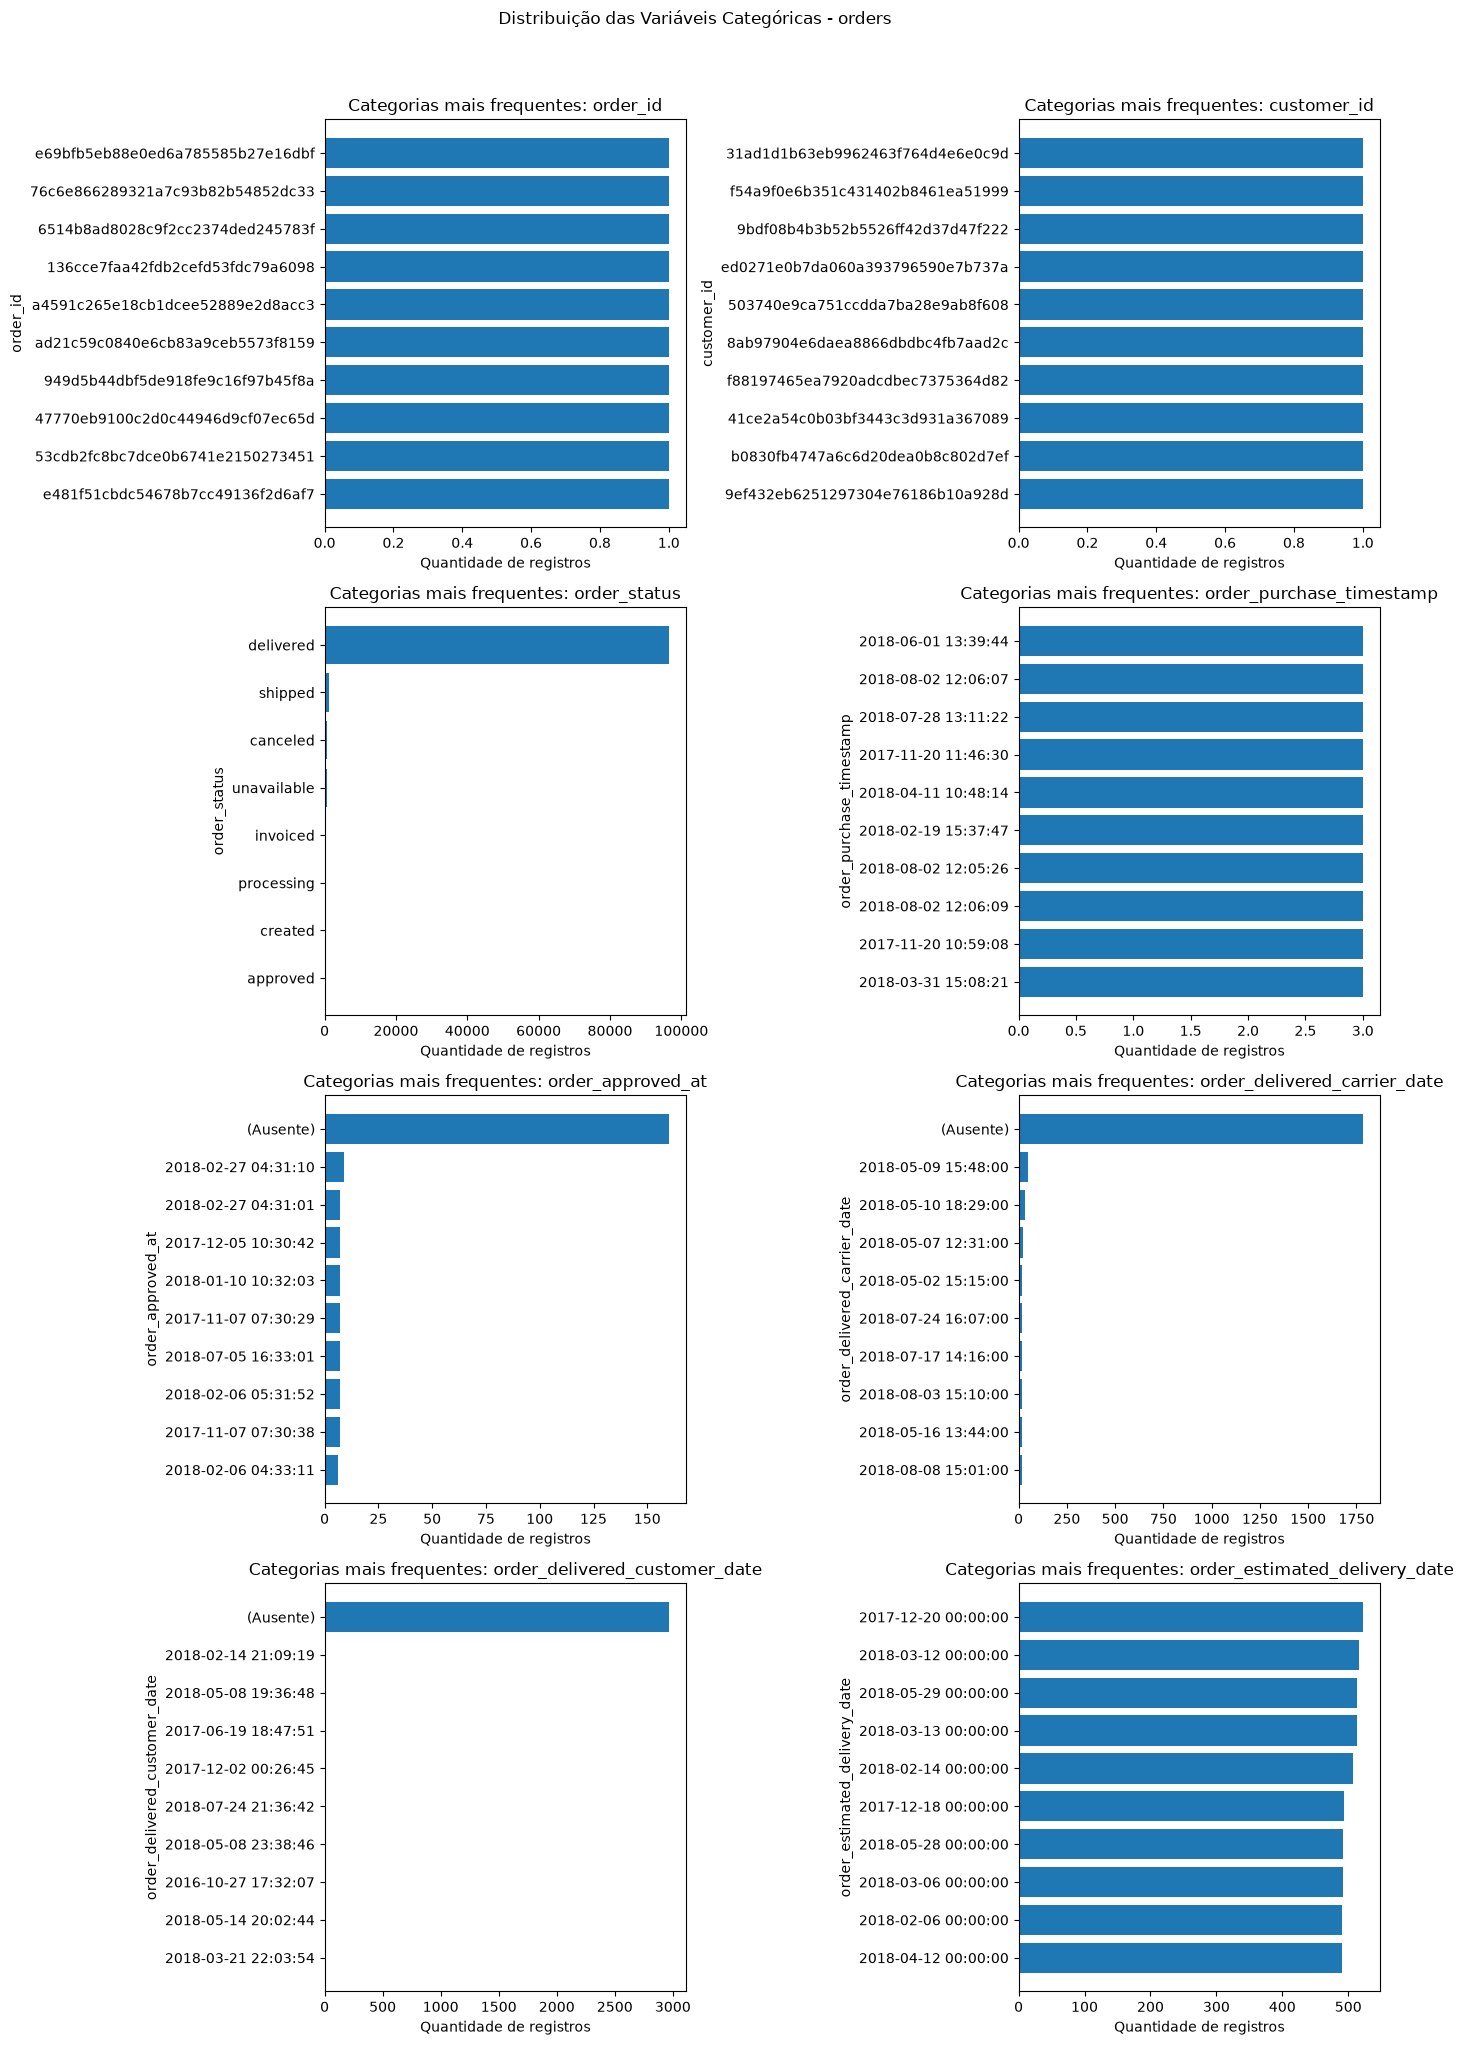


Distribuição das variáveis categóricas: order_items
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_categoricas_order_items.png


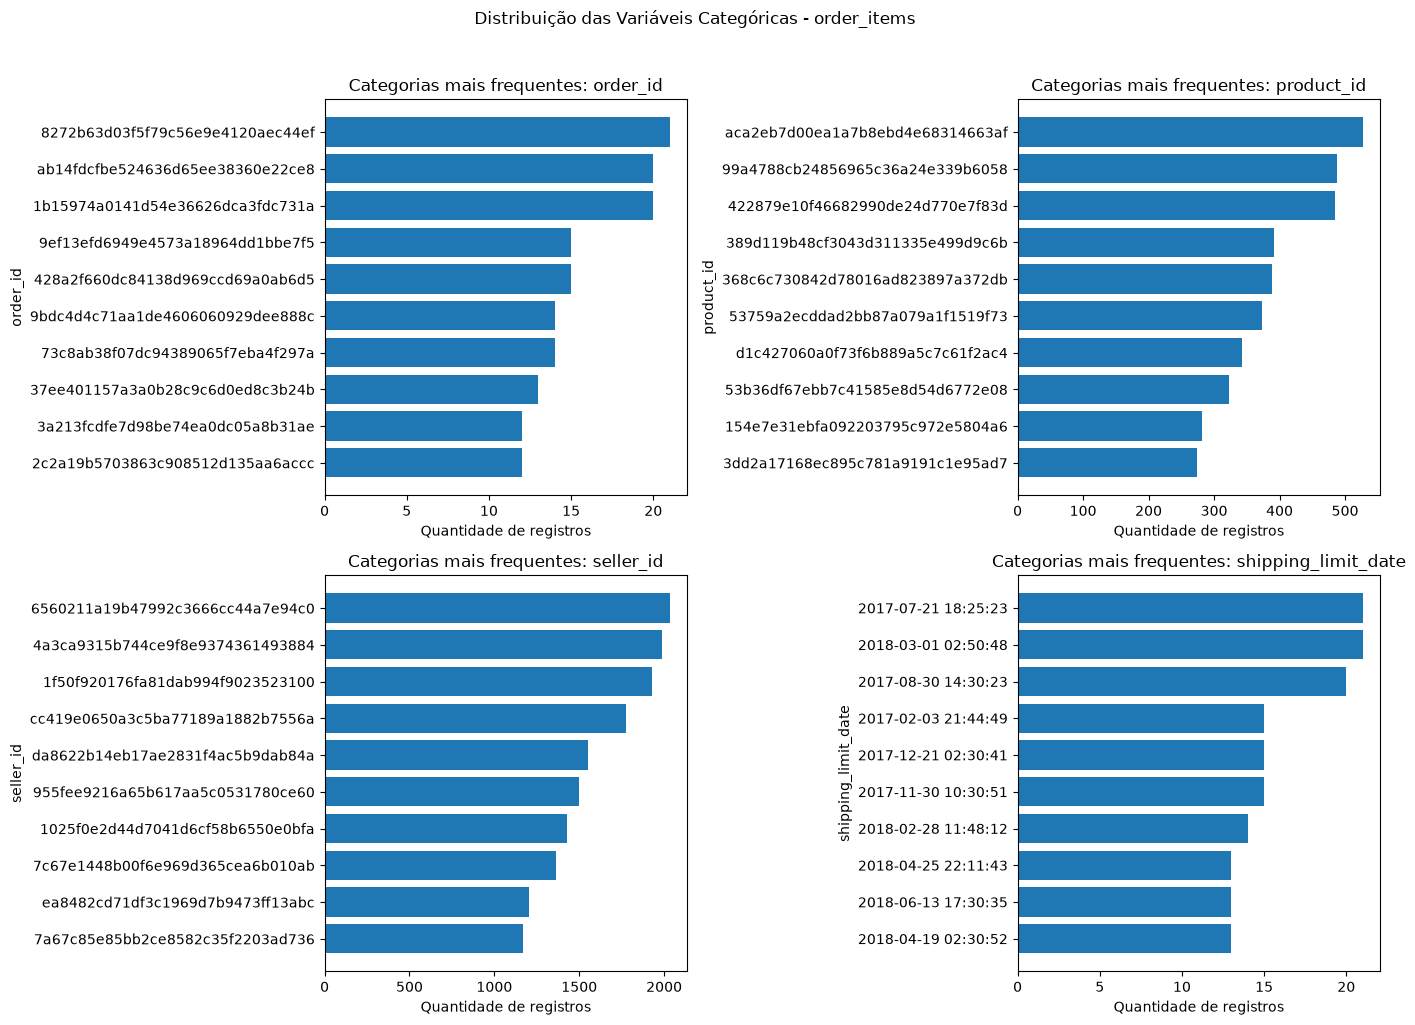


Distribuição das variáveis categóricas: customers
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_categoricas_customers.png


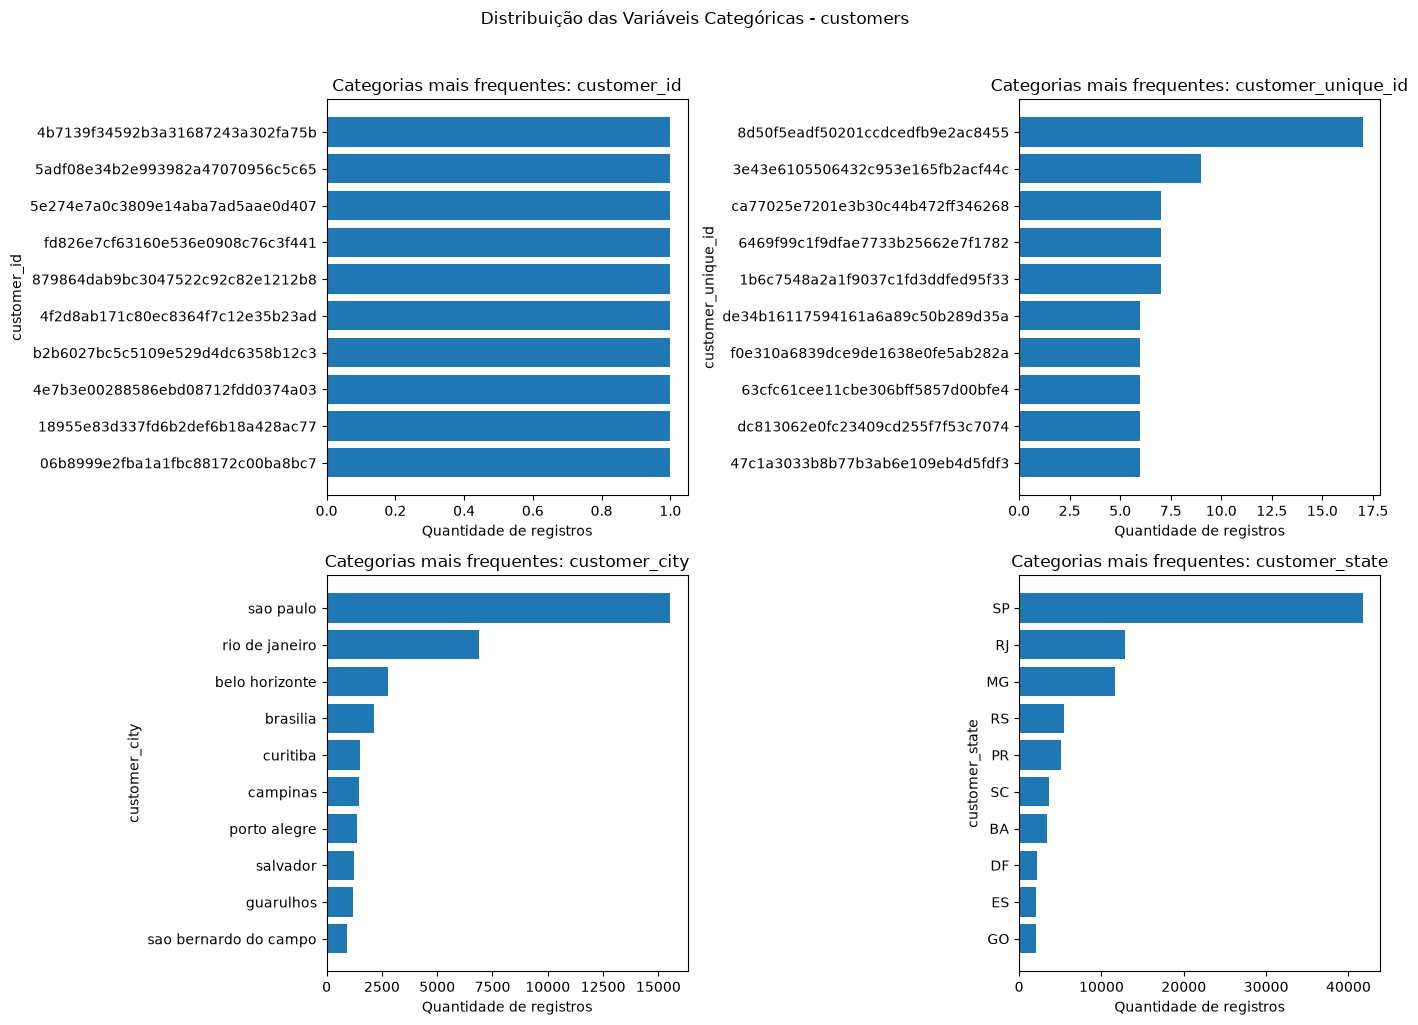


Distribuição das variáveis categóricas: products
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_categoricas_products.png


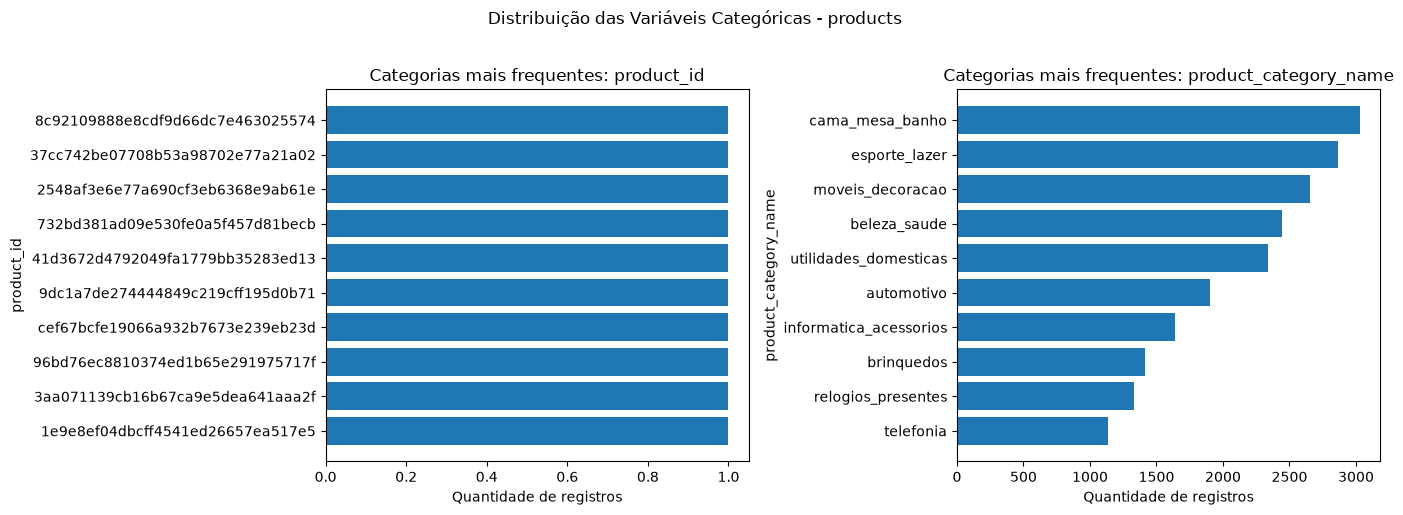


Distribuição das variáveis categóricas: sellers
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\distribuicao_categoricas_sellers.png


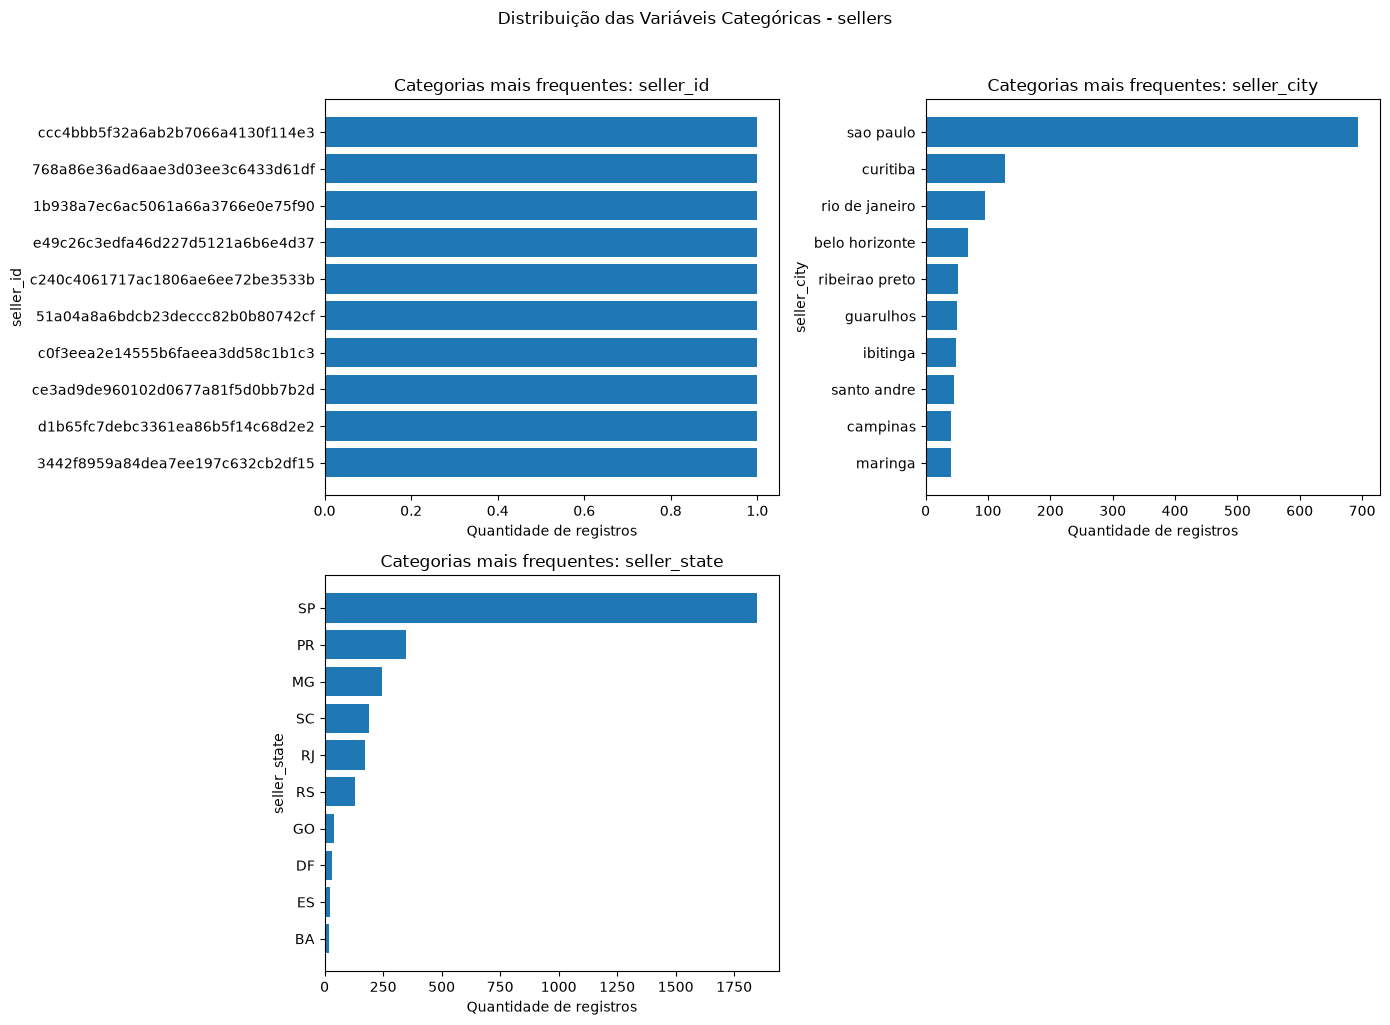

In [29]:
for nome, df in datasets.items():
    print(f"\nDistribuição das variáveis categóricas: {nome}")

    grafico_distribuicao_categoricas(
        df,
        nome=nome,
        top_n=10,
    )

### Análise das distribuições das variáveis categóricas

A análise visual dos gráficos de distribuição das variáveis categóricas dos cinco datasets — `orders`, `order_items`, `customers`, `products` e `sellers` — permitiu observar concentrações de frequência, categorias predominantes e características dos identificadores.

Os gráficos apresentam as dez categorias mais frequentes de cada variável (`top_n=10`), com exceção de `order_status`, que possui oito categorias exibidas. As frequências mencionadas são aproximações visuais, e as conclusões devem considerar essa limitação.

#### Dataset `orders`

A variável `order_status` apresenta forte predominância da categoria `delivered`, enquanto as demais categorias possuem frequências consideravelmente menores.

Nas colunas `order_approved_at`, `order_delivered_carrier_date` e `order_delivered_customer_date`, a categoria `(Ausente)` aparece entre as frequências mais elevadas. Esse padrão é compatível com a existência de pedidos que não chegaram a determinadas etapas do processo, mas essa interpretação depende do status de cada pedido e não pode ser confirmada apenas pelos gráficos.

A variável `order_estimated_delivery_date` apresenta frequências relativamente próximas entre as dez datas mais frequentes. Nessas categorias, os horários exibidos são `00:00:00`, o que sugere um registro com granularidade diária.

Os identificadores `order_id` e `customer_id` apresentam frequência 1 nas barras exibidas. Essa observação visual, isoladamente, não comprova a unicidade em todo o dataset.

#### Dataset `order_items`

Os gráficos apresentam as variáveis `order_id`, `product_id`, `seller_id` e `shipping_limit_date`.

Essas variáveis correspondem a identificadores e a uma data armazenada como texto, não sendo categorias descritivas convencionais. As frequências observadas representam a quantidade de registros associados a cada identificador ou data.

Entre as dez categorias exibidas, alguns pedidos apresentam frequências relativamente elevadas de itens, e determinados produtos e vendedores concentram mais registros do que os demais. Esses resultados descrevem a distribuição das linhas do dataset, mas não permitem, isoladamente, concluir sobre desempenho logístico ou risco de atraso.

#### Dataset `customers`

A variável `customer_id` apresenta frequência 1 nas barras exibidas. Já `customer_unique_id` apresenta repetições, sugerindo que um mesmo identificador de cliente pode estar associado a vários registros. Essa interpretação deve ser considerada em conjunto com a estrutura e a finalidade dessas duas colunas.

Entre as cidades exibidas, `sao paulo` apresenta a maior frequência, seguida de `rio de janeiro` e `belo horizonte`. Na variável `customer_state`, São Paulo (`SP`) lidera, seguido de Rio de Janeiro (`RJ`) e Minas Gerais (`MG`).

Essas frequências indicam concentração geográfica dos registros de clientes nas categorias apresentadas. Como os gráficos mostram apenas as categorias mais frequentes, não representam a distribuição completa de cidades e estados.

#### Dataset `products`

A variável `product_id` apresenta frequência 1 nas barras exibidas, enquanto `product_category_name` mostra maior frequência para `cama_mesa_banho`, seguida de `esporte_lazer` e `moveis_decoracao`.

A distribuição entre as dez categorias de produtos mais frequentes é relativamente gradual, sem a predominância extrema observada em `orders.order_status`.

As frequências representam a quantidade de produtos cadastrados em cada categoria, e não o volume de vendas. A relação entre categorias e vendas exigiria uma análise conjunta com o dataset `order_items`, ainda não contemplada por esses gráficos.

#### Dataset `sellers`

A variável `seller_id` apresenta frequência 1 nas barras exibidas. Na variável `seller_city`, `sao paulo` possui a maior frequência, seguida de `curitiba` e `rio de janeiro`.

Na variável `seller_state`, São Paulo (`SP`) apresenta concentração expressiva em relação aos demais estados exibidos, seguido de Paraná (`PR`) e Minas Gerais (`MG`).

Os resultados indicam concentração geográfica dos registros de vendedores, especialmente em São Paulo. Entretanto, os gráficos não permitem concluir sobre distâncias de entrega ou fluxos logísticos, pois isso exigiria cruzar as localizações dos vendedores e dos clientes.

#### Síntese dos achados

Os gráficos evidenciam a predominância de pedidos com status `delivered`, a presença de valores ausentes entre as categorias mais frequentes de algumas datas de `orders`, a concentração geográfica de clientes e vendedores e a distribuição das categorias de produtos cadastrados.

Também foi observado que algumas variáveis classificadas como categóricas são, na realidade, identificadores ou datas armazenadas como texto. Nesses casos, as frequências devem ser interpretadas considerando a natureza dos dados.

#### Limitações

A análise se restringe às categorias exibidas nos gráficos. Portanto, não permite determinar todas as frequências, quantificar percentuais com precisão ou avaliar integralmente as categorias menos frequentes.

As observações sobre recorrência de clientes, relação entre status e ausência de datas e possíveis fluxos logísticos constituem hipóteses que dependem de verificações adicionais.

### Análise de matriz de correlação


Matriz de correlação: orders
Não há variáveis numéricas suficientes em 'orders' para calcular correlações.

Matriz de correlação: order_items
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\correlacao_order_items.png


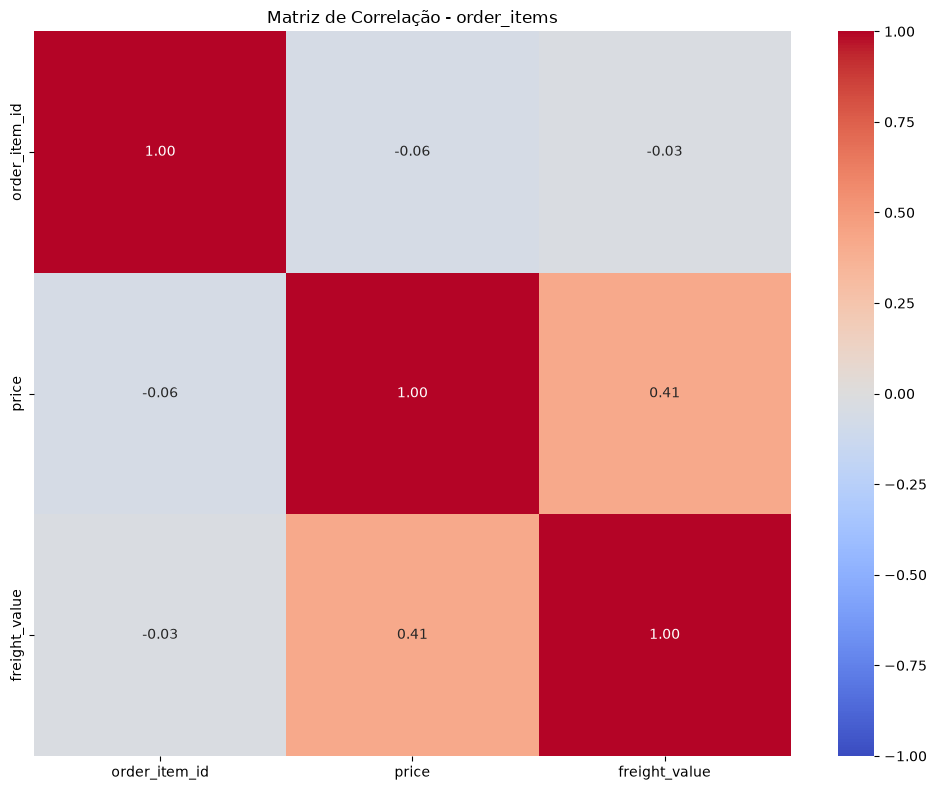


Matriz de correlação: customers
Não há variáveis numéricas suficientes em 'customers' para calcular correlações.

Matriz de correlação: products
Gráfico salvo em: C:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\images\eda\correlacao_products.png


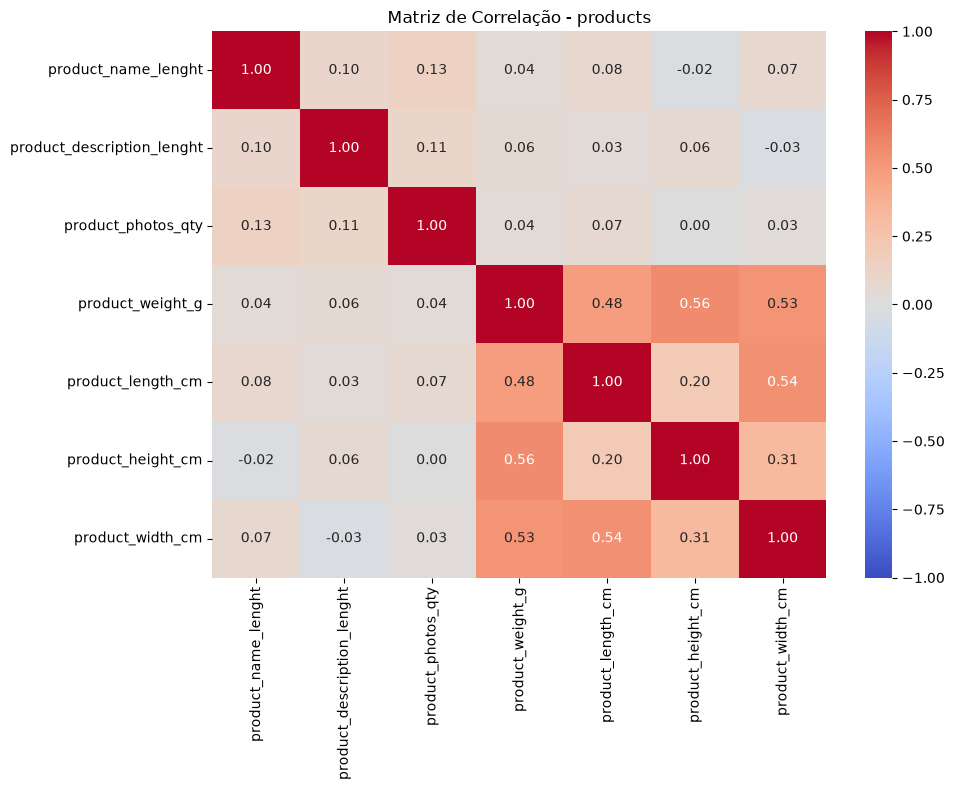


Matriz de correlação: sellers
Não há variáveis numéricas suficientes em 'sellers' para calcular correlações.


In [30]:
for nome, df in datasets.items():
    print(f"\nMatriz de correlação: {nome}")
    grafico_correlacao(df, nome=nome)

### Análise de correlação

Na Fase 2.1, foram geradas matrizes de correlação de Pearson para os datasets `order_items` e `products`, únicos que possuem pelo menos duas colunas reconhecidas como numéricas pelos tipos de dados atuais. A análise descreve associações lineares entre as variáveis numéricas desses datasets.

#### Dataset `order_items`

Observou-se uma correlação positiva moderada entre `price` e `freight_value` (0,41), indicando que valores mais elevados de preço tendem a estar associados a valores mais elevados de frete nos registros analisados.

As correlações de `order_item_id` com `price` (-0,06) e `freight_value` (-0,03) são próximas de zero, indicando associações lineares muito fracas. Como `order_item_id` representa a posição sequencial do item dentro do pedido, essas associações devem ser interpretadas considerando a natureza dessa variável.

#### Dataset `products`

A variável `product_weight_g` apresentou correlações positivas moderadas com `product_height_cm` (0,56), `product_width_cm` (0,53) e `product_length_cm` (0,48).

Entre as dimensões físicas, destacou-se a correlação entre comprimento e largura (0,54). As associações entre altura e largura (0,31) e entre altura e comprimento (0,20) foram menores.

Esses resultados são compatíveis com a hipótese de que produtos com maiores dimensões tendam a apresentar maior peso. Entretanto, as correlações são descritivas e não demonstram causalidade.

As correlações entre `product_name_lenght`, `product_description_lenght` e `product_photos_qty` foram positivas e fracas, variando de 0,10 a 0,13. As associações dessas variáveis com as características físicas dos produtos ficaram próximas de zero, variando de -0,03 a 0,08.

#### Limitações da análise

Os resultados devem ser interpretados considerando que o coeficiente de Pearson mede principalmente a intensidade e a direção das associações lineares entre variáveis numéricas.

As matrizes geradas não incluem testes de significância estatística, intervalos de confiança ou a quantidade de observações válidas utilizada em cada par de variáveis. Além disso, a análise não permite identificar, isoladamente, relações não lineares nem determinar a influência de valores extremos sobre os coeficientes calculados.

As correlações observadas não estabelecem relações de causa e efeito. Nesta fase, os resultados são utilizados para caracterizar os dados, sem realizar transformações, exclusões ou outras intervenções nos datasets.

## Conclusão da Fase 1 — Carregamento, Diagnóstico e Análise Exploratória dos Dados (EDA)

A Fase 1 teve como objetivo carregar os datasets do projeto DeliveryRisk AI, verificar suas características estruturais e realizar uma análise exploratória inicial dos dados, identificando padrões, inconsistências potenciais e aspectos relevantes para as próximas etapas do pipeline.

Foram analisados cinco datasets: `orders`, `order_items`, `customers`, `products` e `sellers`, que totalizam 347.578 registros distribuídos entre diferentes entidades do processo de compra e entrega. A análise estrutural permitiu verificar as dimensões, os tipos de dados, os valores ausentes e a presença de registros duplicados em cada conjunto.

No diagnóstico de valores ausentes, observou-se que o dataset `orders` apresenta ausências principalmente nas colunas relacionadas à aprovação e às etapas de entrega dos pedidos. A análise por status demonstrou que essas ausências estão associadas a diferentes situações do ciclo do pedido, embora sua causa não possa ser determinada apenas pelos dados examinados. No dataset `products`, foram identificados 611 produtos com pelo menos um campo ausente, distribuídos em diferentes padrões de preenchimento.

Não foram encontrados registros integralmente duplicados nos cinco datasets. Também foram verificadas características relevantes das identificações dos registros, como a repetição de `order_id` em `order_items`, compatível com a possibilidade de um pedido conter vários itens, e a ausência de combinações duplicadas de `order_id` e `order_item_id`.

A análise das distribuições numéricas evidenciou assimetrias nas variáveis `price` e `freight_value` de `order_items`, além de diferentes padrões de distribuição nas características dos produtos. Os histogramas também reforçaram a necessidade de considerar a natureza de cada variável durante a interpretação, especialmente no caso de identificadores e códigos postais, que não devem ser tratados como medidas quantitativas convencionais.

Na análise das distribuições categóricas, destacou-se a predominância do status `delivered` em `orders`, a concentração de registros de clientes e vendedores em determinadas cidades e estados e a distribuição das categorias cadastradas em `products`. Também foi observado que algumas colunas classificadas como categóricas contêm identificadores ou datas armazenadas como texto, aspecto importante para a preparação das análises posteriores.

Por fim, as matrizes de correlação de Pearson, geradas para `order_items` e `products`, indicaram uma associação positiva moderada entre preço e frete, assim como associações positivas entre o peso e algumas dimensões físicas dos produtos. As demais relações observadas variaram de fracas a próximas de zero. Esses resultados são descritivos e não permitem estabelecer causalidade.

De modo geral, a Fase 1 permitiu conhecer a estrutura e as principais características dos datasets, documentar os padrões observados e identificar pontos que merecem atenção nas próximas etapas. Os resultados também evidenciam a importância de considerar os diferentes níveis de granularidade e a natureza das variáveis antes de realizar análises integrada.


## Fase 2 — Tratamento e Integração dos Dados

Nesta etapa será realizado o tratamento inicial e a integração dos cinco datasets do Olist, com o objetivo de construir uma base de dados consistente, com granularidade de um registro por pedido e adequada para a preparação das variáveis e o treinamento dos modelos de Machine Learning.

Serão executadas as seguintes ações:

- Carregamento dos cinco datasets utilizando as funções implementadas na etapa anterior;
- Criação de cópias dos datasets em memória, preservando os arquivos originais;
- Conversão e validação das colunas de data utilizadas na análise dos pedidos e na construção da variável-alvo;
- Identificação e validação de chaves identificadoras, valores ausentes e possíveis inconsistências relevantes para a integração;
- Aplicação de tratamentos iniciais necessários, com base nos problemas de qualidade identificados na análise exploratória;
- Agregação dos itens dos pedidos para obter informações consolidadas por pedido, incluindo quantidade de itens, valores de produtos, frete e características de produtos e vendedores;
- Integração dos datasets de pedidos, itens, clientes, produtos e vendedores, respeitando os relacionamentos entre suas chaves;
- Construção da variável-alvo `delivery_delayed`, identificando pedidos entregues após a data estimada e pedidos entregues no prazo;
- Identificação dos pedidos sem datas válidas para determinar o atraso, evitando a atribuição de rótulos incorretos;
- Validação da integridade da base integrada, verificando a granularidade dos registros, a quantidade de pedidos, as correspondências entre datasets e a distribuição da variável-alvo;
- Documentação das decisões de tratamento, dos critérios de elegibilidade para a variável-alvo e dos resultados das validações;
- Preparação da base integrada para a próxima etapa do pipeline, destinada à seleção e preparação das variáveis preditoras para os modelos de Machine Learning.

Os datasets originais serão preservados em `data/raw/`. Os resultados processados serão armazenados em `data/processed/` após a execução e validação do fluxo de tratamento e integração.

### Tratamento Inicial e Validação dos Dados

Nesta etapa, os datasets carregados na fase anterior passam por procedimentos iniciais de tratamento e validação, com o objetivo de garantir a consistência das informações e preparar os dados para a integração.

As atividades incluem a criação de cópias de trabalho para preservar os dados originais, a conversão de colunas de data, a normalização de valores textuais, a validação das chaves e a verificação de valores numéricos. Também são analisados os valores ausentes e as correspondências entre as chaves dos datasets relacionados.

Essas verificações permitem identificar possíveis inconsistências antes da combinação das informações. Os valores ausentes são preservados nesta etapa, sem preenchimentos ou exclusões arbitrárias, para que decisões posteriores considerem o contexto dos dados e os requisitos da modelagem.


In [31]:
datasets_trabalho = {
    nome: df.copy(deep=True)
    for nome, df in datasets.items()
}

print("Datasets preparados para tratamento:")

for nome, df in datasets_trabalho.items():
    print(f"{nome}: {df.shape[0]} linhas, {df.shape[1]} colunas")

Datasets preparados para tratamento:
orders: 99441 linhas, 8 colunas
order_items: 112650 linhas, 7 colunas
customers: 99441 linhas, 5 colunas
products: 32951 linhas, 9 colunas
sellers: 3095 linhas, 4 colunas


In [32]:
colunas_obrigatorias = {
    "orders": [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": [
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value",
        "shipping_limit_date"
    ],
    "customers": [
        "customer_id",
        "customer_city",
        "customer_state"
    ],
    "products": [
        "product_id",
        "product_category_name",
        "product_name_lenght",
        "product_description_lenght",
        "product_photos_qty",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ],
    "sellers": [
        "seller_id",
        "seller_city",
        "seller_state"
    ]
}

for nome, colunas in colunas_obrigatorias.items():
    validar_colunas(
        df=datasets_trabalho[nome],
        colunas=colunas,
        nome_dataset=nome
    )

    print(f"Dataset '{nome}': colunas obrigatórias validadas.")

Dataset 'orders': colunas obrigatórias validadas.
Dataset 'order_items': colunas obrigatórias validadas.
Dataset 'customers': colunas obrigatórias validadas.
Dataset 'products': colunas obrigatórias validadas.
Dataset 'sellers': colunas obrigatórias validadas.


### **Validação das colunas obrigatórias**

A função `validar_colunas()` foi utilizada para verificar se os datasets possuem as colunas necessárias para as operações de tratamento e integração.

A validação foi aplicada aos datasets `orders`, `order_items`, `customers`, `products` e `sellers`, considerando as colunas obrigatórias definidas para cada conjunto de dados.

A função verifica se todas as colunas informadas estão presentes no respectivo DataFrame. Caso alguma coluna obrigatória esteja ausente, a execução gera um erro indicando quais colunas não foram encontradas.

Essa verificação contribui para identificar problemas estruturais antes da execução das transformações, reduzindo a possibilidade de erros nas etapas posteriores do pipeline.

In [33]:
colunas_data_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

(
    datasets_trabalho["orders"],
    relatorio_datas_orders
) = converter_colunas_para_data(
    df=datasets_trabalho["orders"],
    colunas=colunas_data_orders,
    nome_dataset="orders"
)

display(relatorio_datas_orders)

,dataset,coluna,ausentes_antes,datas_invalidas,ausentes_depois
0,orders,order_purchase_timestamp,0,0,0
1,orders,order_approved_at,160,0,160
2,orders,order_delivered_carrier_date,1783,0,1783
3,orders,order_delivered_customer_date,2965,0,2965
4,orders,order_estimated_delivery_date,0,0,0


In [34]:
datasets_trabalho["orders"][colunas_data_orders].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [35]:
datasets_trabalho["order_items"], relatorio_datas_itens = converter_colunas_para_data(
    df=datasets_trabalho["order_items"],
    colunas=["shipping_limit_date"],
    nome_dataset="order_items"
)

display(relatorio_datas_itens)

display(
    datasets_trabalho["order_items"][
        ["shipping_limit_date"]
    ].dtypes
)

,dataset,coluna,ausentes_antes,datas_invalidas,ausentes_depois
0,order_items,shipping_limit_date,0,0,0


shipping_limit_date    datetime64[us]
dtype: object

In [36]:
for nome, df in datasets_trabalho.items():
    colunas_textuais = df.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()

    print(f"{nome}: {colunas_textuais}")

orders: ['order_id', 'customer_id', 'order_status']
order_items: ['order_id', 'product_id', 'seller_id']
customers: ['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']
products: ['product_id', 'product_category_name']
sellers: ['seller_id', 'seller_city', 'seller_state']


In [37]:
relatorios_normalizacao = {}

for nome, df in datasets_trabalho.items():
    datasets_trabalho[nome] = normalizar_texto(
        df=df,
        nome_dataset=nome
    )

    relatorios_normalizacao[nome] = {
        "linhas": len(datasets_trabalho[nome]),
        "colunas": len(datasets_trabalho[nome].columns),
        "valores_ausentes": int(
            datasets_trabalho[nome].isna().sum().sum()
        )
    }

display(pd.DataFrame(relatorios_normalizacao).T)

,linhas,colunas,valores_ausentes
orders,99441,8,4908
order_items,112650,7,0
customers,99441,5,0
products,32951,9,2448
sellers,3095,4,0


In [38]:
comparacao_normalizacao = []

for nome in datasets:
    ausentes_antes = int(datasets[nome].isna().sum().sum())
    ausentes_depois = int(
        datasets_trabalho[nome].isna().sum().sum()
    )

    comparacao_normalizacao.append({
        "dataset": nome,
        "ausentes_antes": ausentes_antes,
        "ausentes_depois": ausentes_depois,
        "diferenca": ausentes_depois - ausentes_antes
    })

display(pd.DataFrame(comparacao_normalizacao))

,dataset,ausentes_antes,ausentes_depois,diferenca
0,orders,4908,4908,0
1,order_items,0,0,0
2,customers,0,0,0
3,products,2448,2448,0
4,sellers,0,0,0


In [39]:
chaves_datasets = {
    "orders": ["order_id"],
    "order_items": ["order_id", "order_item_id"],
    "customers": ["customer_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"]
}

relatorios_chaves = []

for nome, colunas_chave in chaves_datasets.items():
    resultado = validar_chaves(
        df=datasets_trabalho[nome],
        colunas=colunas_chave,
        nome_dataset=nome
    )

    relatorios_chaves.append(resultado)

relatorio_chaves = pd.DataFrame(relatorios_chaves)
display(relatorio_chaves)

,dataset,colunas_chave,total_registros,registros_com_chave_ausente,registros_em_chaves_duplicadas,ocorrencias_duplicadas_alem_da_primeira,chave_unica_valida
0,orders,[order_id],99441,0,0,0,True
1,order_items,"[order_id, order_item_id]",112650,0,0,0,True
2,customers,[customer_id],99441,0,0,0,True
3,products,[product_id],32951,0,0,0,True
4,sellers,[seller_id],3095,0,0,0,True


In [40]:
colunas_numericas = {
    "order_items": [
        "order_item_id",
        "price",
        "freight_value"
    ],
    "products": [
        "product_name_lenght",
        "product_description_lenght",
        "product_photos_qty",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
}

relatorios_numericos = []

for nome, colunas in colunas_numericas.items():
    relatorio = validar_valores_numericos(
        df=datasets_trabalho[nome],
        colunas=colunas,
        nome_dataset=nome
    )

    relatorios_numericos.append(relatorio)

relatorio_numerico = pd.concat(
    relatorios_numericos,
    ignore_index=True
)

display(relatorio_numerico)

,dataset,coluna,valores_ausentes,valores_nao_numericos,valores_infinitos
0,order_items,order_item_id,0,0,0
1,order_items,price,0,0,0
2,order_items,freight_value,0,0,0
3,products,product_name_lenght,610,0,0
4,products,product_description_lenght,610,0,0
5,products,product_photos_qty,610,0,0
6,products,product_weight_g,2,0,0
7,products,product_length_cm,2,0,0
8,products,product_height_cm,2,0,0
9,products,product_width_cm,2,0,0


In [41]:
relatorios_qualidade = {}

for nome, df in datasets_trabalho.items():
    resumo, resumo_colunas = resumir_qualidade_dados(
        df=df,
        nome_dataset=nome
    )

    relatorios_qualidade[nome] = resumo

    print(f"\nDataset: {nome}")
    display(resumo_colunas)


Dataset: orders


,coluna,tipo_dado,valores_ausentes,percentual_ausente,valores_distintos
0,order_id,str,0,0.00,99441
1,customer_id,str,0,0.00,99441
2,order_status,str,0,0.00,8
3,order_purchase_timestamp,datetime64[us],0,0.00,98875
4,order_approved_at,datetime64[us],160,0.16,90733
5,order_delivered_carrier_date,datetime64[us],1783,1.79,81018
6,order_delivered_customer_date,datetime64[us],2965,2.98,95664
7,order_estimated_delivery_date,datetime64[us],0,0.00,459



Dataset: order_items


,coluna,tipo_dado,valores_ausentes,percentual_ausente,valores_distintos
0,order_id,str,0,0.0,98666
1,order_item_id,int64,0,0.0,21
2,product_id,str,0,0.0,32951
3,seller_id,str,0,0.0,3095
4,shipping_limit_date,datetime64[us],0,0.0,93318
5,price,float64,0,0.0,5968
6,freight_value,float64,0,0.0,6999



Dataset: customers


,coluna,tipo_dado,valores_ausentes,percentual_ausente,valores_distintos
0,customer_id,str,0,0.0,99441
1,customer_unique_id,str,0,0.0,96096
2,customer_zip_code_prefix,int64,0,0.0,14994
3,customer_city,str,0,0.0,4119
4,customer_state,str,0,0.0,27



Dataset: products


,coluna,tipo_dado,valores_ausentes,percentual_ausente,valores_distintos
0,product_id,str,0,0.00,32951
1,product_category_name,str,610,1.85,73
2,product_name_lenght,float64,610,1.85,66
3,product_description_lenght,float64,610,1.85,2960
4,product_photos_qty,float64,610,1.85,19
5,product_weight_g,float64,2,0.01,2204
6,product_length_cm,float64,2,0.01,99
7,product_height_cm,float64,2,0.01,102
8,product_width_cm,float64,2,0.01,95



Dataset: sellers


,coluna,tipo_dado,valores_ausentes,percentual_ausente,valores_distintos
0,seller_id,str,0,0.0,3095
1,seller_zip_code_prefix,int64,0,0.0,2246
2,seller_city,str,0,0.0,611
3,seller_state,str,0,0.0,23


In [42]:

ids_pedidos = set(datasets_trabalho["orders"]["order_id"])
ids_pedidos_itens = set(datasets_trabalho["order_items"]["order_id"])

ids_clientes = set(datasets_trabalho["customers"]["customer_id"])
ids_clientes_pedidos = set(datasets_trabalho["orders"]["customer_id"])

ids_produtos = set(datasets_trabalho["products"]["product_id"])
ids_produtos_itens = set(datasets_trabalho["order_items"]["product_id"])

ids_vendedores = set(datasets_trabalho["sellers"]["seller_id"])
ids_vendedores_itens = set(datasets_trabalho["order_items"]["seller_id"])

relatorio_correspondencias = pd.DataFrame([
    {
        "relacionamento": "orders → order_items",
        "chaves_sem_correspondencia": len(ids_pedidos_itens - ids_pedidos)
    },
    {
        "relacionamento": "orders → customers",
        "chaves_sem_correspondencia": len(ids_clientes_pedidos - ids_clientes)
    },
    {
        "relacionamento": "order_items → products",
        "chaves_sem_correspondencia": len(ids_produtos_itens - ids_produtos)
    },
    {
        "relacionamento": "order_items → sellers",
        "chaves_sem_correspondencia": len(ids_vendedores_itens - ids_vendedores)
    }
])

display(relatorio_correspondencias)

,relacionamento,chaves_sem_correspondencia
0,orders → order_items,0
1,orders → customers,0
2,order_items → products,0
3,order_items → sellers,0


## Tratamento Inicial e Validação dos Dados

Nesta etapa, foram realizadas as primeiras operações de tratamento e validação dos datasets utilizados no projeto DeliveryRisk AI. O objetivo foi preparar os dados para a etapa posterior de integração, preservando os arquivos originais e verificando a consistência das informações.

### Criação de cópias para tratamento

Os cinco datasets carregados — `orders`, `order_items`, `customers`, `products` e `sellers` — foram copiados para a estrutura `datasets_trabalho`. As transformações foram aplicadas nessas cópias, mantendo os dados originais carregados sem alterações.

### Conversão de colunas de data

As colunas de data dos datasets `orders` e `order_items` foram convertidas para o tipo `datetime64[us]`.

No dataset `orders`, foram convertidas as seguintes colunas:

- `order_purchase_timestamp`
- `order_approved_at`
- `order_delivered_carrier_date`
- `order_delivered_customer_date`
- `order_estimated_delivery_date`

No dataset `order_items`, foi convertida a coluna `shipping_limit_date`.

Os relatórios de conversão não identificaram datas inválidas nas colunas verificadas. As ausências já existentes foram preservadas, sem preenchimento artificial.

### Normalização de texto

A função `normalizar_texto()` foi aplicada aos cinco datasets de trabalho. Essa operação realiza a normalização prevista na função implementada, incluindo a remoção de espaços em branco nas extremidades dos valores textuais e a conversão de textos vazios em valores ausentes.

Após a execução, não houve alteração na quantidade total de valores ausentes dos datasets.

### Validação das chaves

Foram verificadas as chaves utilizadas para identificar os registros e relacionar os datasets:

| Dataset | Chave validada |
|---|---|
| `orders` | `order_id` |
| `order_items` | `order_id` e `order_item_id` |
| `customers` | `customer_id` |
| `products` | `product_id` |
| `sellers` | `seller_id` |

Os resultados indicaram ausência de valores ausentes nas chaves e ausência de duplicações nas chaves verificadas. A chave composta de `order_items`, formada por `order_id` e `order_item_id`, também passou na validação.

### Validação dos valores numéricos

Foram verificadas as colunas numéricas selecionadas dos datasets `order_items` e `products`.

No dataset `order_items`, foram analisadas as colunas `order_item_id`, `price` e `freight_value`. Nenhuma apresentou valores ausentes, não numéricos ou infinitos.

No dataset `products`, foram analisadas as colunas de comprimento do nome, comprimento da descrição, quantidade de fotos, peso e dimensões do produto. Não foram encontrados valores não numéricos ou infinitos nas colunas verificadas.

As ausências identificadas em `products` foram preservadas:

- 610 valores ausentes em cada uma das colunas `product_name_lenght`, `product_description_lenght` e `product_photos_qty`;
- 610 valores ausentes em `product_category_name`;
- 2 valores ausentes em cada uma das colunas de peso e dimensões físicas.

Esses valores serão considerados nas decisões posteriores de preparação dos dados e modelagem, sem preenchimento ou exclusão arbitrária nesta etapa.

### Resumo da qualidade dos dados

Após a execução ordenada das células, foi gerado um novo resumo da qualidade dos cinco datasets. Os resultados confirmaram os tipos de dados esperados, incluindo as colunas de data convertidas, e permitiram revisar a quantidade de valores ausentes e distintos por coluna.

Os valores ausentes observados em `orders` e `products` permaneceram preservados. Não foram realizadas exclusões de registros nem imputações nesta etapa.

### Validação das correspondências entre chaves

Foram verificadas as correspondências entre os identificadores dos datasets relacionados:

| Relacionamento | Chaves sem correspondência |
|---|---:|
| `orders` → `order_items` | 0 |
| `orders` → `customers` | 0 |
| `order_items` → `products` | 0 |
| `order_items` → `sellers` | 0 |

Não foram encontradas chaves sem correspondência nas quatro relações verificadas. Esse resultado indica que os identificadores presentes no lado dependente de cada relação existem no respectivo dataset de referência.

### Resultado da etapa

O tratamento inicial e as validações previstas até este ponto foram concluídos. Os datasets de trabalho apresentam as conversões de data esperadas, as chaves verificadas são válidas e não foram identificadas chaves órfãs nas relações analisadas.

### Agregação e Integração dos Dados

Nesta etapa, os datasets tratados e validados anteriormente são combinados para construir uma base integrada, com uma linha por pedido, reunindo informações sobre pedidos, clientes, itens, produtos e vendedores.

As atividades incluem a agregação dos itens por pedido, o enriquecimento das informações com dados de produtos e vendedores, a integração com os datasets de pedidos e clientes e a criação da variável-alvo `delivery_delayed`, que identifica se uma entrega ocorreu após a data estimada.

Ao final, são realizadas validações da base integrada, verificando a quantidade de registros, a unicidade dos pedidos, as correspondências entre os datasets e a distribuição da variável-alvo. Essas verificações preparam os dados para as próximas etapas do pipeline.

In [43]:
base_integrada, relatorios_integracao = construir_base_integrada(
    datasets_trabalho
)

print("Dimensões da base integrada:", base_integrada.shape)

print("\nRelatório da validação:")
display(
    pd.DataFrame([relatorios_integracao["validacao"]])
)

print("\nResumo da variável-alvo:")
display(
    pd.DataFrame([relatorios_integracao["resumo_alvo"]])
)

Dimensões da base integrada: (99441, 29)

Relatório da validação:


,total_linhas,pedidos_distintos,pedidos_com_id_ausente,linhas_em_pedidos_duplicados,uma_linha_por_pedido,quantidade_pedidos_esperada,quantidade_pedidos_compativel,valores_alvo_ausentes,valores_alvo_invalidos
0,99441,99441,0,0,True,99441,True,2965,0



Resumo da variável-alvo:


,total_pedidos,entregas_atrasadas,entregas_no_prazo,pedidos_sem_alvo,percentual_atrasados_entre_elegiveis
0,99441,7827,88649,2965,8.11


In [44]:
relatorio_sem_itens = investigar_pedidos_sem_itens(
    base_integrada
)

print(
    "Total de pedidos sem itens:",
    relatorio_sem_itens["total_pedidos_sem_itens"],
)

print("\nValores ausentes nas colunas agregadas:")
display(relatorio_sem_itens["ausencias_colunas_itens"])

print(
    "\nPedidos sem itens com variável-alvo preenchida:",
    relatorio_sem_itens[
        "pedidos_sem_itens_com_alvo_preenchido"
    ],
)

Total de pedidos sem itens: 775

Valores ausentes nas colunas agregadas:


,valores_ausentes
quantidade_itens,775
valor_total_produtos,775
frete_total,775
quantidade_produtos_distintos,775
quantidade_vendedores_distintos,775
categoria_produto_mais_frequente,775
quantidade_categorias_distintas,775
product_weight_g_medio,775
product_length_cm_medio,775
product_height_cm_medio,775



Pedidos sem itens com variável-alvo preenchida: 0


In [45]:
pedidos_com_datas = base_integrada[
    "order_delivered_customer_date"
].notna() & base_integrada[
    "order_estimated_delivery_date"
].notna()

alvo_recalculado = (
    base_integrada.loc[
        pedidos_com_datas,
        "order_delivered_customer_date"
    ]
    >
    base_integrada.loc[
        pedidos_com_datas,
        "order_estimated_delivery_date"
    ]
).astype("int64")

alvo_atual = base_integrada.loc[
    pedidos_com_datas,
    "delivery_delayed"
].astype("int64")

divergencias = (
    alvo_recalculado != alvo_atual
).sum()

print("Pedidos com as duas datas disponíveis:", pedidos_com_datas.sum())
print("Divergências na variável-alvo:", divergencias)

Pedidos com as duas datas disponíveis: 96476
Divergências na variável-alvo: 0


In [46]:
raiz_projeto = Path.cwd().parents[1]
caminho_processados = raiz_projeto / "data" / "processed"

caminho_processados.mkdir(parents=True, exist_ok=True)

caminho_arquivo = caminho_processados / "base_integrada.parquet"

base_integrada.to_parquet(
    caminho_arquivo,
    index=False,
)

print("Base integrada salva em:", caminho_arquivo)
print("Arquivo existe:", caminho_arquivo.exists())

Base integrada salva em: c:\Users\franc\OneDrive\Desktop\Projetos\Curso\DeliveryRisk_AI\data\processed\base_integrada.parquet
Arquivo existe: True


## Agregação e Integração dos Dados

Nesta etapa, foram realizadas a agregação dos itens por pedido e a integração dos datasets utilizados no projeto DeliveryRisk AI. O objetivo foi construir uma base consolidada, com uma linha por pedido, reunindo informações dos pedidos, clientes, produtos e vendedores, além de criar e validar a variável-alvo utilizada na previsão de atrasos nas entregas.

### Agregação dos itens por pedido

Os registros do dataset `order_items` foram agregados por `order_id` para consolidar as informações dos itens de cada pedido. Para complementar os dados, foram utilizadas informações dos datasets `products` e `sellers`, por meio das respectivas chaves de relacionamento.

A agregação gerou informações resumidas sobre os itens, incluindo quantidades, valores de produtos e frete, categorias de produtos e características dos produtos e vendedores.

O dataset `order_items` continha 112.650 registros, que foram consolidados em 98.666 pedidos com itens. Não foram identificados IDs de pedido ausentes ou duplicados no resultado da agregação.

Não foram encontradas correspondências ausentes entre os itens e os registros de produtos e vendedores utilizados no processo.

### Integração dos datasets

Após a agregação, as informações foram integradas ao dataset `orders`, incorporando também os dados dos clientes disponíveis no dataset `customers`.

A agregação prévia dos itens permitiu integrar as informações sem multiplicar as linhas dos pedidos que continham vários itens.

A base integrada resultante apresentou as seguintes características:

| Indicador | Resultado |
|---|---:|
| Total de registros | 99.441 |
| Total de colunas | 29 |
| IDs de pedido distintos | 99.441 |
| IDs de pedido ausentes | 0 |
| Linhas pertencentes a pedidos duplicados | 0 |
| Pedidos sem itens | 775 |

A quantidade de registros da base integrada corresponde à quantidade esperada de pedidos do dataset `orders`. A validação confirmou que a base mantém uma linha por pedido e que não existem IDs ausentes ou pedidos duplicados.

Os 775 pedidos sem itens foram preservados na base integrada. Como não possuem registros correspondentes no dataset `order_items`, suas informações derivadas da agregação permanecem ausentes.

### Criação e validação da variável-alvo

Foi criada a variável `delivery_delayed` para identificar se um pedido foi entregue após a data estimada.

A classificação utiliza as datas efetiva e estimada de entrega:

- **1 — Entrega atrasada:** a data efetiva de entrega é posterior à data estimada.
- **0 — Entrega no prazo:** a data efetiva de entrega é igual ou anterior à data estimada.
- **Valor ausente:** não existem as informações de data necessárias para determinar a classificação.

O resumo da variável-alvo apresentou os seguintes resultados:

| Indicador | Quantidade |
|---|---:|
| Total de pedidos | 99.441 |
| Entregas atrasadas | 7.827 |
| Entregas no prazo | 88.649 |
| Pedidos sem classificação | 2.965 |
| Pedidos com classificação válida | 96.476 |

Entre os pedidos com classificação válida, aproximadamente 8,11% apresentaram atraso.

Foi realizada uma verificação independente da variável-alvo nos 96.476 pedidos que possuíam as duas datas necessárias. O resultado foi de **zero divergências**, confirmando a correspondência entre a regra definida e os valores calculados.

Os 2.965 pedidos sem classificação foram mantidos sem atribuição artificial de rótulos, pois não havia informações suficientes para determinar se as entregas ocorreram no prazo.

### Investigação dos pedidos sem itens

Foi realizada uma investigação específica dos 775 pedidos sem registros correspondentes no dataset `order_items`.

A análise identificou valores ausentes nas 15 colunas originadas da agregação dos itens. Cada uma dessas colunas apresentou 775 valores ausentes correspondentes aos pedidos sem itens.

Também foi verificado que nenhum dos 775 pedidos sem itens possuía a variável-alvo preenchida.

Esses resultados foram registrados para orientar as decisões posteriores de preparação dos dados. Os pedidos foram mantidos na base, sem exclusão arbitrária ou preenchimento artificial das informações agregadas.

### Validação da base integrada

Após a integração, foi executada a função de validação para verificar a consistência estrutural da base consolidada.

Os resultados confirmaram que:

- A base possui 99.441 linhas e 29 colunas.
- Existem 99.441 IDs de pedido distintos.
- Não existem IDs de pedido ausentes.
- Não existem linhas pertencentes a pedidos duplicados.
- A quantidade de pedidos é compatível com a quantidade esperada.
- A variável-alvo possui 2.965 valores ausentes.
- Não foram encontrados valores inválidos na variável-alvo.

As verificações confirmaram que a integração preservou a granularidade definida e que a base atende aos critérios estruturais estabelecidos para esta etapa.

### Salvamento da base integrada

Após a construção e as validações, a base integrada foi salva no formato Parquet no seguinte caminho:

`data/processed/base_integrada.parquet`

O salvamento foi confirmado pela existência do arquivo no diretório `data/processed/` da raiz do projeto.

O formato Parquet foi utilizado para armazenar os dados processados de maneira eficiente e permitir sua reutilização nas próximas etapas sem a necessidade de executar novamente todas as operações de agregação e integração, desde que os dados de origem e as regras de processamento permaneçam inalterados.

### Resultado da etapa

A etapa de agregação e integração dos dados foi concluída. A base integrada contém 99.441 pedidos e 29 colunas, mantendo uma linha por pedido e sem duplicações de `order_id`.

A variável-alvo `delivery_delayed` foi criada e validada, os pedidos sem itens foram investigados e os valores ausentes relevantes foram preservados e documentados. A base integrada também foi salva em `data/processed/base_integrada.parquet` para utilização nas próximas etapas do pipeline.


## Conclusão Geral da Fase 2 — Tratamento e Integração dos Dados

A Fase 2 do projeto DeliveryRisk AI teve como objetivo preparar, validar e integrar os dados necessários para as próximas etapas do pipeline de Machine Learning. As atividades envolveram o tratamento inicial dos datasets, a verificação da qualidade e consistência dos dados, a agregação dos itens por pedido, a integração das informações e a criação e validação da variável-alvo `delivery_delayed`.

Durante o tratamento inicial, foram preservados os datasets originais, enquanto as transformações foram aplicadas às cópias de trabalho. As colunas de data foram convertidas para os tipos apropriados, os textos foram normalizados e as chaves e os valores numéricos selecionados foram validados. Também foram verificadas as correspondências entre os identificadores dos datasets relacionados, sem a identificação de chaves sem correspondência nas relações analisadas. Os valores ausentes existentes foram preservados para avaliação nas etapas posteriores.

Na etapa de agregação e integração, os 112.650 registros de `order_items` foram consolidados em 98.666 pedidos com itens. Em seguida, as informações agregadas foram integradas aos dados de pedidos e clientes, resultando em uma base com **99.441 registros e 29 colunas**, mantendo uma linha por pedido. As validações confirmaram a ausência de IDs de pedido ausentes e de registros duplicados, além da compatibilidade entre a quantidade de pedidos da base integrada e a quantidade esperada do dataset `orders`.

A variável-alvo `delivery_delayed` foi criada para identificar entregas atrasadas e entregas realizadas no prazo. Dos 99.441 pedidos, 96.476 possuíam as informações necessárias para a classificação, dos quais 7.827 foram identificados como atrasados e 88.649 como entregues no prazo. A verificação independente da regra de classificação não identificou divergências. Os 2.965 pedidos sem informações suficientes para determinar o resultado foram mantidos com a variável-alvo ausente, evitando a atribuição de classificações sem respaldo nos dados.

A investigação dos 775 pedidos sem itens identificou valores ausentes nas 15 colunas derivadas da agregação. Esses registros foram preservados na base, e suas ausências foram documentadas para orientar as decisões posteriores de preparação dos dados. Dessa forma, as limitações identificadas foram registradas sem a realização de exclusões ou preenchimentos artificiais nesta fase.

Por fim, a base integrada foi salva no formato Parquet em `data/processed/base_integrada.parquet`, permitindo sua reutilização nas próximas etapas do projeto sem a necessidade de repetir todo o processo de agregação e integração, desde que as entradas e as regras de processamento permaneçam inalteradas.

**Conclui-se que a Fase 2 foi concluída**, com a preparação e a validação dos dados, a construção de uma base integrada na granularidade de pedido e a criação de uma variável-alvo validada. A base resultante constitui a entrada para as próximas etapas do pipeline, nas quais serão avaliadas as estratégias de tratamento dos valores ausentes, a seleção e preparação das variáveis e os demais procedimentos necessários ao desenvolvimento dos modelos de Machine Learning.

## Fase 3 — Pré-processamento e Engenharia de Atributos

Nesta etapa será realizada a preparação da base integrada para o treinamento dos modelos de Machine Learning, com o objetivo de selecionar as variáveis preditoras, criar atributos relevantes e definir um pipeline de pré-processamento que garanta a consistência dos dados e evite o vazamento de informações.

Serão executadas as seguintes ações:

- Filtragem dos pedidos elegíveis para a análise, considerando os critérios definidos na etapa anterior para a construção da variável-alvo;
- Criação de atributos temporais a partir da data e hora da compra, incluindo ano, mês, dia do mês, dia da semana, hora e indicação de fim de semana;
- Seleção das variáveis preditoras, excluindo identificadores, informações indisponíveis no momento da compra e colunas relacionadas à variável-alvo;
- Prevenção do vazamento de informações, garantindo que as variáveis utilizadas representem informações disponíveis no momento da previsão;
- Classificação das variáveis preditoras em numéricas e categóricas, considerando também o tratamento específico do prefixo do CEP do cliente como variável categórica;
- Validação da seleção das variáveis, verificando a presença de colunas proibidas, duplicidades e a classificação de todas as features;
- Análise dos valores ausentes nas variáveis preditoras, identificando sua distribuição e investigando as principais causas das ausências observadas;
- Definição das estratégias de imputação, utilizando a mediana para variáveis numéricas e a categoria mais frequente para variáveis categóricas;
- Configuração do pré-processamento das variáveis numéricas por meio da imputação e padronização, e das variáveis categóricas por meio da imputação e codificação One-Hot Encoding;
- Criação e inspeção do pipeline de pré-processamento, utilizando `ColumnTransformer` para aplicar as transformações adequadas a cada tipo de variável;
- Validação dos atributos temporais e da estrutura final das variáveis preditoras, verificando a consistência dos dados preparados;
- Documentação das decisões de engenharia de atributos, seleção de variáveis, tratamento de valores ausentes e prevenção de vazamento de informações;
- Preparação dos dados e do pipeline de pré-processamento para a próxima etapa, destinada à divisão dos dados em conjuntos de treinamento, validação e teste.

O pipeline de pré-processamento será configurado nesta etapa, mas seus transformadores não serão ajustados sobre a base completa. O ajuste será realizado posteriormente, utilizando exclusivamente os dados de treinamento, após a divisão dos dados, para evitar vazamento de informações entre os conjuntos.

In [47]:
base_elegivel = filtrar_pedidos_elegiveis(
    base_integrada
)

Dimensões da base elegível: (96476, 29)

Distribuição do alvo:
delivery_delayed
0    88649
1     7827
Name: count, dtype: Int64

Taxa de atraso:
0.0811


In [48]:

base_temporal = criar_atributos_temporais(
    base_elegivel
)

print("Dimensões da base temporal:", base_temporal.shape)

print("\nAtributos temporais criados:")
colunas_temporais = [
    "ano_compra",
    "mes_compra",
    "dia_mes_compra",
    "dia_semana_compra",
    "hora_compra",
    "fim_de_semana_compra"
]

print(
    base_temporal[
        colunas_temporais
    ].head()
)

Dimensões da base temporal: (96476, 34)

Atributos temporais criados:
   ano_compra  mes_compra  dia_mes_compra  dia_semana_compra  hora_compra  \
0        2017          10               2                  0           10   
1        2018           7              24                  1           20   
2        2018           8               8                  2            8   
3        2017          11              18                  5           19   
4        2018           2              13                  1           21   

   fim_de_semana_compra  
0                 False  
1                 False  
2                 False  
3                  True  
4                 False  


In [49]:
X, y, relatorio_features = definir_features(
    base_temporal
)

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

print("\nRelatório de features:")
print(relatorio_features)

Dimensões de X: (96476, 24)
Dimensões de y: (96476,)

Relatório de features:
{'coluna_alvo': 'delivery_delayed', 'features_selecionadas': ['customer_zip_code_prefix', 'customer_city', 'customer_state', 'quantidade_itens', 'valor_total_produtos', 'frete_total', 'quantidade_produtos_distintos', 'quantidade_vendedores_distintos', 'categoria_produto_mais_frequente', 'quantidade_categorias_distintas', 'product_weight_g_medio', 'product_length_cm_medio', 'product_height_cm_medio', 'product_width_cm_medio', 'seller_state_mais_frequente', 'quantidade_estados_vendedores_distintos', 'seller_city_mais_frequente', 'quantidade_cidades_vendedores_distintas', 'ano_compra', 'mes_compra', 'dia_mes_compra', 'dia_semana_compra', 'hora_compra', 'fim_de_semana_compra'], 'colunas_excluidas': ['order_id', 'customer_id', 'customer_unique_id', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_status', 'delivery_delayed', 'alvo_elegivel', 'order_approved_at', 'order_estimated_delivery_date

In [50]:
colunas_dimensoes = [
    "product_weight_g_medio",
    "product_length_cm_medio",
    "product_height_cm_medio",
    "product_width_cm_medio",
]

print("Pedidos com alguma dimensão ausente:")
print(
    X[colunas_dimensoes]
    .isna()
    .any(axis=1)
    .sum()
)

print("\nCombinações de ausências nas dimensões:")
display(
    X[colunas_dimensoes]
    .isna()
    .value_counts()
)

Pedidos com alguma dimensão ausente:
16

Combinações de ausências nas dimensões:


product_weight_g_medio  product_length_cm_medio  product_height_cm_medio  product_width_cm_medio
False                   False                    False                    False                     96460
True                    True                     True                     True                         16
Name: count, dtype: int64

In [51]:
print("Pedidos sem categoria de produto:")
print(
    X["categoria_produto_mais_frequente"]
    .isna()
    .sum()
)

print("\nDimensões ausentes nos pedidos sem categoria:")
display(
    X.loc[
        X["categoria_produto_mais_frequente"].isna(),
        colunas_dimensoes
    ]
    .isna()
    .sum()
)

Pedidos sem categoria de produto:
1332

Dimensões ausentes nos pedidos sem categoria:


product_weight_g_medio     15
product_length_cm_medio    15
product_height_cm_medio    15
product_width_cm_medio     15
dtype: int64

In [52]:

colunas_dimensoes = [
    "product_weight_g_medio",
    "product_length_cm_medio",
    "product_height_cm_medio",
    "product_width_cm_medio",
]

mascara_dimensoes_ausentes = (
    X[colunas_dimensoes].isna().all(axis=1)
)

ids_pedidos_sem_dimensoes = base_temporal.loc[
    X.index[mascara_dimensoes_ausentes],
    "order_id"
]


pedidos_sem_dimensoes = base_integrada.loc[
    base_integrada["order_id"].isin(ids_pedidos_sem_dimensoes)
].copy()

print(
    "Quantidade de pedidos com dimensões ausentes:",
    len(pedidos_sem_dimensoes)
)

Quantidade de pedidos com dimensões ausentes: 16


In [53]:
order_items = datasets["order_items"]

print("Dimensões de order_items:", order_items.shape)

Dimensões de order_items: (112650, 7)


In [54]:
ids_pedidos = pedidos_sem_dimensoes["order_id"]

itens_desses_pedidos = order_items.loc[
    order_items["order_id"].isin(ids_pedidos)
].copy()

quantidade_itens = (
    itens_desses_pedidos
    .groupby("order_id")
    .size()
    .rename("quantidade_itens")
)

resumo_itens = (
    pedidos_sem_dimensoes[["order_id"]]
    .merge(
        quantidade_itens,
        on="order_id",
        how="left"
    )
)

resumo_itens["quantidade_itens"] = (
    resumo_itens["quantidade_itens"]
    .fillna(0)
    .astype(int)
)

display(resumo_itens)

print(
    "\nPedidos sem itens associados:",
    (resumo_itens["quantidade_itens"] == 0).sum()
)

print(
    "Pedidos com itens associados:",
    (resumo_itens["quantidade_itens"] > 0).sum()
)

,order_id,quantidade_itens
0,6e150190fbe04c642a9cf0b80d83ee16,1
1,d38dcb503cd4ddc6ce7702552918bd8f,2
2,ddf16d77e858a32f36e10c289a28ef61,1
3,1521c6bb7b1028154c8c67cf80fa809f,1
4,e3daea0200104991cb979c2fcc509ae7,1
5,415cfaaaa8cea49f934470548797fed1,2
6,85f8ad45e067abd694b627859fa57453,1
7,101157d4fae1c9fb74a00a5dee265c25,1
8,bf49f84a0580ef6751e13357776b7ed9,1
9,bbfc7badbed2f1828e22b6d629201bd4,1



Pedidos sem itens associados: 0
Pedidos com itens associados: 16


In [55]:
products = datasets["products"]

itens_com_produtos = itens_desses_pedidos.merge(
    products[
        [
            "product_id",
            "product_weight_g",
            "product_length_cm",
            "product_height_cm",
            "product_width_cm",
        ]
    ],
    on="product_id",
    how="left",
    indicator=True,
)

display(
    itens_com_produtos[
        [
            "order_id",
            "product_id",
            "product_weight_g",
            "product_length_cm",
            "product_height_cm",
            "product_width_cm",
            "_merge",
        ]
    ]
)

print("\nCorrespondência dos produtos:")
print(itens_com_produtos["_merge"].value_counts())

print("\nProdutos com todas as dimensões ausentes:")
colunas_dimensoes_produto = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

print(
    itens_com_produtos[colunas_dimensoes_produto]
    .isna()
    .all(axis=1)
    .sum()
)

,order_id,product_id,product_weight_g,product_length_cm,product_height_cm,product_width_cm,_merge
0,101157d4fae1c9fb74a00a5dee265c25,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
1,1521c6bb7b1028154c8c67cf80fa809f,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
2,415cfaaaa8cea49f934470548797fed1,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
3,415cfaaaa8cea49f934470548797fed1,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
4,595316a07cd3dea9db7adfcc7e247ae7,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
5,6e150190fbe04c642a9cf0b80d83ee16,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
6,6f497c40431d5fb0cfbd6c943dd29215,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
7,85f8ad45e067abd694b627859fa57453,09ff539a621711667c43eba6a3bd8466,NaN,NaN,NaN,NaN,both
8,a2456e7f02197951664897a94c87242d,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both
9,a7a43f469c0d7bdb0a23a82db125aefa,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,both



Correspondência dos produtos:
_merge
both          18
left_only      0
right_only     0
Name: count, dtype: int64

Produtos com todas as dimensões ausentes:
18


In [56]:
ids_produtos_sem_dimensoes = itens_com_produtos["product_id"].unique()

produtos_sem_dimensoes = products.loc[
    products["product_id"].isin(ids_produtos_sem_dimensoes)
].copy()


resumo_ausentes_produtos = pd.DataFrame({
    "quantidade_ausentes": produtos_sem_dimensoes.isna().sum(),
    "percentual_ausentes": (
        produtos_sem_dimensoes.isna().mean() * 100
    ).round(2),
})

resumo_ausentes_produtos = resumo_ausentes_produtos[
    resumo_ausentes_produtos["quantidade_ausentes"] > 0
].sort_values(
    "quantidade_ausentes",
    ascending=False
)

print(
    "Quantidade de produtos únicos analisados:",
    produtos_sem_dimensoes["product_id"].nunique()
)

display(resumo_ausentes_produtos)

Quantidade de produtos únicos analisados: 2


,quantidade_ausentes,percentual_ausentes
product_weight_g,2,100.0
product_length_cm,2,100.0
product_height_cm,2,100.0
product_width_cm,2,100.0
product_category_name,1,50.0
product_name_lenght,1,50.0
product_description_lenght,1,50.0
product_photos_qty,1,50.0


In [57]:

colunas_relevantes = [
    "product_id",
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

display(
    produtos_sem_dimensoes[colunas_relevantes]
)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:
colunas_numericas, colunas_categoricas = separar_tipos_features(X)

print("Quantidade de variáveis numéricas:",
      len(colunas_numericas))

print("Quantidade de variáveis categóricas:",
      len(colunas_categoricas))

print(
    "\nCEP classificado como categórico:",
    "customer_zip_code_prefix" in colunas_categoricas
)

Quantidade de variáveis numéricas: 17
Quantidade de variáveis categóricas: 7

CEP classificado como categórico: True


In [59]:
colunas_classificadas = (
    colunas_numericas + colunas_categoricas
)

print(
    "Todas as features foram classificadas:",
    set(colunas_classificadas) == set(X.columns)
)

print(
    "Nenhuma feature foi classificada mais de uma vez:",
    len(colunas_classificadas) == len(set(colunas_classificadas))
)

print(
    "Quantidade de features:",
    len(X.columns)
)

Todas as features foram classificadas: True
Nenhuma feature foi classificada mais de uma vez: True
Quantidade de features: 24


In [60]:

relatorio_validacao = validar_features(X)

print(relatorio_validacao)

{'quantidade_linhas': 96476, 'quantidade_features': 24, 'colunas': ['customer_zip_code_prefix', 'customer_city', 'customer_state', 'quantidade_itens', 'valor_total_produtos', 'frete_total', 'quantidade_produtos_distintos', 'quantidade_vendedores_distintos', 'categoria_produto_mais_frequente', 'quantidade_categorias_distintas', 'product_weight_g_medio', 'product_length_cm_medio', 'product_height_cm_medio', 'product_width_cm_medio', 'seller_state_mais_frequente', 'quantidade_estados_vendedores_distintos', 'seller_city_mais_frequente', 'quantidade_cidades_vendedores_distintas', 'ano_compra', 'mes_compra', 'dia_mes_compra', 'dia_semana_compra', 'hora_compra', 'fim_de_semana_compra'], 'valores_ausentes_total': 1396, 'colunas_com_ausencias': ['categoria_produto_mais_frequente', 'product_weight_g_medio', 'product_length_cm_medio', 'product_height_cm_medio', 'product_width_cm_medio'], 'features_validas': True}


In [61]:
pipeline_preprocessamento = criar_pipeline_preprocessamento(
    colunas_numericas=colunas_numericas,
    colunas_categoricas=colunas_categoricas
)

print(pipeline_preprocessamento)

ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalonador',
                                                  StandardScaler())]),
                                 ['quantidade_itens', 'valor_total_produtos',
                                  'frete_total',
                                  'quantidade_produtos_distintos',
                                  'quantidade_vendedores_distintos',
                                  'quantidade_categorias_distintas',
                                  'product_weight_g_medio',
                                  'product_length_cm_medio'...
                                ('categoricas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='most_frequent')),
            

In [62]:

resumo_ausentes = pd.DataFrame({
    "quantidade_ausentes": X.isna().sum(),
    "percentual_ausentes": (
        X.isna().mean() * 100
    ).round(2),
})

resumo_ausentes = (
    resumo_ausentes[
        resumo_ausentes["quantidade_ausentes"] > 0
    ]
    .sort_values(
        "quantidade_ausentes",
        ascending=False
    )
)

display(resumo_ausentes)

,quantidade_ausentes,percentual_ausentes
categoria_produto_mais_frequente,1332,1.38
product_weight_g_medio,16,0.02
product_length_cm_medio,16,0.02
product_height_cm_medio,16,0.02
product_width_cm_medio,16,0.02


In [63]:
print("Transformadores da pipeline:\n")

for nome, transformador, colunas in pipeline_preprocessamento.transformers:
    print(f"Transformador: {nome}")
    print(f"Colunas: {colunas}")
    print(f"Configuração:\n{transformador}")
    print("-" * 60)

print("\nQuantidade de variáveis numéricas:",
      len(colunas_numericas))

print("Quantidade de variáveis categóricas:",
      len(colunas_categoricas))

print("\nTotal de features classificadas:",
      len(colunas_numericas) + len(colunas_categoricas))

print("Quantidade de features em X:",
      X.shape[1])

Transformadores da pipeline:

Transformador: numericas
Colunas: ['quantidade_itens', 'valor_total_produtos', 'frete_total', 'quantidade_produtos_distintos', 'quantidade_vendedores_distintos', 'quantidade_categorias_distintas', 'product_weight_g_medio', 'product_length_cm_medio', 'product_height_cm_medio', 'product_width_cm_medio', 'quantidade_estados_vendedores_distintos', 'quantidade_cidades_vendedores_distintas', 'ano_compra', 'mes_compra', 'dia_mes_compra', 'dia_semana_compra', 'hora_compra']
Configuração:
Pipeline(steps=[('imputador', SimpleImputer(strategy='median')),
                ('escalonador', StandardScaler())])
------------------------------------------------------------
Transformador: categoricas
Colunas: ['customer_city', 'customer_state', 'categoria_produto_mais_frequente', 'seller_state_mais_frequente', 'seller_city_mais_frequente', 'fim_de_semana_compra', 'customer_zip_code_prefix']
Configuração:
Pipeline(steps=[('imputador', SimpleImputer(strategy='most_frequent')),


In [64]:
datas_compra = pd.to_datetime(
    base_elegivel["order_purchase_timestamp"],
    errors="coerce"
)

print(
    "Datas de compra ausentes na origem:",
    base_elegivel["order_purchase_timestamp"].isna().sum()
)

print(
    "Datas de compra inválidas após conversão:",
    datas_compra.isna().sum()
)

print(
    "Atributos temporais com valores ausentes:"
)

colunas_temporais = [
    "ano_compra",
    "mes_compra",
    "dia_mes_compra",
    "dia_semana_compra",
    "hora_compra",
    "fim_de_semana_compra",
]

display(
    base_temporal[colunas_temporais]
    .isna()
    .sum()
    .rename("quantidade_ausentes")
    .to_frame()
)

Datas de compra ausentes na origem: 0
Datas de compra inválidas após conversão: 0
Atributos temporais com valores ausentes:


,quantidade_ausentes
ano_compra,0
mes_compra,0
dia_mes_compra,0
dia_semana_compra,0
hora_compra,0
fim_de_semana_compra,0


## Conclusão da Fase 3 — Pré-processamento e Engenharia de Atributos

A Fase 2.3 foi concluída com a preparação das variáveis preditoras da base integrada e a configuração do pipeline de pré-processamento para as próximas etapas do projeto.

Durante esta fase, foram realizadas as seguintes atividades:

- Filtragem dos pedidos elegíveis para a modelagem, respeitando os critérios definidos na construção da variável-alvo;
- Criação de seis atributos temporais derivados da data e hora da compra;
- Seleção de 24 variáveis preditoras, excluindo identificadores, informações posteriores à compra e colunas que poderiam causar vazamento de informações;
- Classificação das variáveis preditoras em 17 numéricas e 7 categóricas, com o prefixo do CEP do cliente tratado como variável categórica;
- Análise dos valores ausentes, identificando a necessidade de imputação em atributos categóricos e nas dimensões físicas dos produtos;
- Investigação das ausências nas dimensões físicas, constatando que elas estão relacionadas a informações incompletas no cadastro de dois produtos, e não a falhas na integração dos datasets;
- Validação dos atributos temporais, sem identificação de datas ausentes ou inválidas na base elegível e sem valores ausentes nos seis atributos temporais criados;
- Implementação e inspeção do pipeline de pré-processamento, utilizando imputação pela mediana e padronização para variáveis numéricas, além de imputação pela categoria mais frequente e codificação One-Hot Encoding para variáveis categóricas;
- Validação da seleção das variáveis preditoras, confirmando a ausência de colunas proibidas e a classificação de todas as 24 features.

O pipeline foi configurado, mas seus transformadores ainda não foram ajustados aos dados. Essa decisão evita que informações dos futuros conjuntos de validação e teste influenciem o pré-processamento, pois o ajuste será realizado exclusivamente com os dados de treinamento após a divisão dos dados.

Ao final desta fase, a base elegível está preparada para a etapa de divisão dos dados, com as variáveis preditoras selecionadas, os atributos temporais construídos e as estratégias de pré-processamento definidas.

## Fase 4 — Divisão temporal dos dados

A divisão será realizada cronologicamente, usando `order_purchase_timestamp` apenas para definir os conjuntos, sem adicioná-la às 24 features. Os períodos aprovados são: treino até fevereiro de 2018, validação de março a maio de 2018 e teste de junho a agosto de 2018.

O pipeline de pré-processamento permanece sem ajuste nesta etapa. Seus transformadores deverão ser ajustados exclusivamente com `X_train` durante o fluxo de treinamento.


In [65]:
(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
) = dividir_dados_temporalmente(
    X=X,
    y=y,
    base_elegivel=base_elegivel,
)

print("Divisão temporal concluída.")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)


Divisão temporal concluída.
X_train: (57323, 24) | y_train: (57323,)
X_val:   (20550, 24) | y_val:   (20550,)
X_test:  (18603, 24) | y_test:  (18603,)


In [66]:
resumo_divisao = validar_divisao_temporal(
    X=X,
    y=y,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    base_elegivel=base_elegivel,
    pipeline_preprocessamento=pipeline_preprocessamento,
)

display(resumo_divisao)


Validações concluídas: alinhamento, cobertura dos registros, ausência de sobreposição e ordem temporal.


,conjunto,data_inicial,data_final,quantidade_pedidos,pedidos_atrasados,pedidos_no_prazo,taxa_atraso_pct,quantidade_features
0,Treino,2016-09-15 12:16:38,2018-02-28 23:57:55,57323,4395,52928,7.67,24
1,Validação,2018-03-01 00:00:00,2018-05-31 23:51:24,20550,2413,18137,11.74,24
2,Teste,2018-06-01 00:39:55,2018-08-29 15:00:37,18603,1019,17584,5.48,24


## Conclusão da Etapa 4 — Divisão temporal entre treino, validação e teste

Nesta etapa, foi implementada a divisão temporal dos dados elegíveis em três conjuntos: treino, validação e teste. A estratégia adotada respeita a ordem cronológica dos pedidos, simulando a utilização do modelo em dados de períodos futuros.

Os conjuntos foram definidos conforme os seguintes intervalos:

- **Treino:** pedidos realizados até 28 de fevereiro de 2018.
- **Validação:** pedidos realizados entre 1º de março e 31 de maio de 2018.
- **Teste:** pedidos realizados entre 1º de junho e 31 de agosto de 2018.

A divisão foi realizada sobre os 96.476 pedidos elegíveis, preservando as 24 features selecionadas na etapa anterior.

### Resultados da divisão

| Conjunto | Quantidade de pedidos | Pedidos atrasados | Pedidos no prazo | Taxa de atraso |
|---|---:|---:|---:|---:|
| Treino | 57.323 | 4.395 | 52.928 | 7,67% |
| Validação | 20.550 | 2.413 | 18.137 | 11,74% |
| Teste | 18.603 | 1.019 | 17.584 | 5,48% |
| **Total** | **96.476** | **7.827** | **88.649** | **8,11%** |

### Validações realizadas

Foram implementadas e executadas verificações para confirmar:

- A unicidade dos índices e o alinhamento entre as features e a variável-alvo.
- A ausência de sobreposição de registros entre os conjuntos.
- A preservação de todos os registros após a divisão.
- O cumprimento dos intervalos temporais definidos.
- A ordem cronológica entre treino, validação e teste.
- A consistência das 24 features nos três conjuntos.

Todas as validações executadas foram concluídas com sucesso.

### Considerações finais

A Etapa 4 foi concluída com a implementação e validação da divisão temporal dos dados. Os conjuntos `X_train`, `y_train`, `X_val`, `y_val`, `X_test` e `y_test` estão preparados para serem utilizados nas etapas posteriores do projeto.

O pipeline de pré-processamento foi criado na etapa anterior, mas permaneceu sem ajuste nesta fase. Seu ajuste deverá ocorrer posteriormente, utilizando exclusivamente os dados de treino, para evitar vazamento de informações entre os conjuntos.


## Fase 5 — Treinamento e avaliação inicial dos modelos

Nesta etapa, serão treinados e avaliados modelos de classificação para prever o risco de atraso nas entregas. Serão comparados os algoritmos Regressão Logística, Random Forest e Gradient Boosting, utilizando diferentes configurações de hiperparâmetros e os dados de treino e validação definidos na etapa anterior.

A avaliação considerará métricas como precisão, recall, F1-score e ROC-AUC, além dos tempos de treinamento e predição. Também será analisado o impacto de diferentes limiares de classificação sobre as métricas e a quantidade de pedidos classificados como atrasados. O conjunto de teste permanecerá reservado para a avaliação final, sem ser utilizado na seleção dos modelos ou dos limiares.


In [73]:
configuracoes = definir_configuracoes_modelos()

colunas_numericas, colunas_categoricas = separar_tipos_features(X_train)

print("Quantidade de features numéricas:", len(colunas_numericas))
print("Quantidade de features categóricas:", len(colunas_categoricas))

for nome, experimentos in configuracoes.items():
    print(f"{nome}: {len(experimentos)} configurações")

Quantidade de features numéricas: 17
Quantidade de features categóricas: 7
Logistic Regression: 6 configurações
Random Forest: 6 configurações
Gradient Boosting: 6 configurações


### Regressão Logística (Logistic Regression)

Nesta etapa serão implementados e avaliados modelos de Regressão Logística para a classificação de pedidos com risco de atraso nas entregas do e-commerce.

A Regressão Logística é um algoritmo de aprendizado supervisionado que estima a probabilidade de um pedido pertencer à classe de atraso, permitindo classificá-lo como atrasado ou não atrasado a partir das características disponíveis no momento da compra.

Para os experimentos, serão definidas e comparadas diferentes configurações do hiperparâmetro `C`, que controla a intensidade da regularização, e do parâmetro `class_weight`, que permite atribuir pesos diferentes às classes, buscando lidar com o desequilíbrio entre pedidos atrasados e não atrasados.

Durante os experimentos, as diferentes combinações serão avaliadas utilizando o conjunto de validação, considerando métricas como precisão, recall, F1-score e ROC-AUC. Também serão registrados os tempos de treinamento e predição, permitindo comparar o desempenho do modelo com os demais algoritmos.

In [74]:
resultados_logistica = executar_experimentos(
    nome_modelo="Logistic Regression",
    configuracoes=configuracoes["Logistic Regression"],
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    colunas_numericas=colunas_numericas,
    colunas_categoricas=colunas_categoricas,
)

tabela_logistica = registrar_resultados(resultados_logistica)

display(tabela_logistica)

Logistic Regression — experimento 1/6: {'C': 0.01, 'class_weight': 'balanced'}
Acurácia: 0.3433 | Precisão: 0.1292 | Recall: 0.8002 | F1: 0.2225 | ROC-AUC: 0.5963 | Treinamento: 2.62s | Predição: 0.53s
Logistic Regression — experimento 2/6: {'C': 0.1, 'class_weight': None}
Acurácia: 0.8796 | Precisão: 0.2095 | Recall: 0.0091 | F1: 0.0175 | ROC-AUC: 0.5990 | Treinamento: 2.82s | Predição: 0.56s
Logistic Regression — experimento 3/6: {'C': 0.1, 'class_weight': 'balanced'}
Acurácia: 0.4536 | Precisão: 0.1407 | Recall: 0.7153 | F1: 0.2351 | ROC-AUC: 0.6038 | Treinamento: 3.30s | Predição: 2.01s
Logistic Regression — experimento 4/6: {'C': 1.0, 'class_weight': None}
Acurácia: 0.8695 | Precisão: 0.2070 | Recall: 0.0394 | F1: 0.0662 | ROC-AUC: 0.5983 | Treinamento: 4.34s | Predição: 0.52s
Logistic Regression — experimento 5/6: {'C': 1.0, 'class_weight': 'balanced'}
Acurácia: 0.5999 | Precisão: 0.1519 | Recall: 0.5255 | F1: 0.2357 | ROC-AUC: 0.5902 | Treinamento: 6.34s | Predição: 0.51s
Logist

,modelo,experimento,hiperparametros,accuracy,precision,recall,f1,roc_auc,tempo_treinamento_s,tempo_predicao_s
0,Logistic Regression,5,"{'C': 1.0, 'class_weight': 'balanced'}",0.599903,0.151947,0.525487,0.235732,0.590158,6.335345,0.510197
1,Logistic Regression,3,"{'C': 0.1, 'class_weight': 'balanced'}",0.453577,0.140691,0.715292,0.235134,0.603805,3.297021,2.009305
2,Logistic Regression,1,"{'C': 0.01, 'class_weight': 'balanced'}",0.343260,0.129207,0.800249,0.222491,0.596283,2.617154,0.532142
3,Logistic Regression,6,"{'C': 10.0, 'class_weight': 'balanced'}",0.658978,0.151630,0.414422,0.222025,0.576694,9.666987,0.497778
4,Logistic Regression,4,"{'C': 1.0, 'class_weight': None}",0.869489,0.206972,0.039370,0.066156,0.598266,4.337504,0.521937
5,Logistic Regression,2,"{'C': 0.1, 'class_weight': None}",0.879611,0.209524,0.009117,0.017474,0.599019,2.824927,0.563207


## Análise dos resultados da Regressão Logística

Foram avaliadas seis combinações dos hiperparâmetros `C` e `class_weight`, utilizando o conjunto de validação para comparar o desempenho das configurações na identificação de pedidos com risco de atraso.

Os resultados apresentaram acurácias entre **34,33% e 87,96%**. A maior acurácia foi obtida no **Experimento 2**, com `C=0.1` e `class_weight=None`, alcançando **87,96%**. Entretanto, essa configuração apresentou recall de apenas **0,91%** e F1-score de **0,0175**, indicando que identificou uma parcela muito pequena dos pedidos realmente atrasados. Esse resultado demonstra que a acurácia, isoladamente, não é suficiente para avaliar o desempenho do modelo diante do desequilíbrio entre as classes.

Em relação ao parâmetro `class_weight`, as configurações com `class_weight="balanced"` apresentaram recalls significativamente superiores às configurações sem ponderação de classes. O maior recall foi obtido no **Experimento 1**, com `C=0.01` e `class_weight="balanced"`, alcançando **80,02%**. No entanto, sua precisão foi de **12,92%**, com F1-score de **0,2225**. Isso indica que o modelo identificou a maior parte dos pedidos atrasados, mas também classificou muitos pedidos não atrasados incorretamente como atrasados.

Entre as seis configurações, o maior F1-score foi obtido no **Experimento 5**, com `C=1.0` e `class_weight="balanced"`, atingindo **0,2357**, com precisão de **15,19%** e recall de **52,55%**. Já o maior ROC-AUC foi observado no **Experimento 3**, com `C=0.1` e `class_weight="balanced"`, alcançando **0,6038**, indicando uma capacidade limitada de distinguir pedidos atrasados dos não atrasados.

Quanto ao tempo de treinamento, os valores variaram entre **2,62 e 9,67 segundos**. O menor tempo foi registrado no Experimento 1, enquanto o maior ocorreu no Experimento 6, com `C=10.0` e `class_weight="balanced"`. O tempo de predição variou entre **0,50 e 2,01 segundos**, com o maior valor registrado no Experimento 3.

Com base nos resultados obtidos no conjunto de validação, o **Experimento 5** apresentou o melhor F1-score entre as configurações de Regressão Logística avaliadas.

### Random Forest

Nesta etapa serão implementados e avaliados modelos Random Forest para a classificação de pedidos com risco de atraso nas entregas do e-commerce.

O Random Forest é um algoritmo de aprendizado supervisionado que combina várias árvores de decisão para realizar classificações. Cada árvore produz uma previsão, e o modelo combina os resultados para determinar a classe final do pedido, permitindo identificar padrões associados aos atrasos nas entregas.

Para os experimentos, serão definidas e comparadas diferentes configurações dos hiperparâmetros `n_estimators`, que determina a quantidade de árvores utilizadas, e `max_depth`, que limita a profundidade máxima de cada árvore. Também será avaliado o parâmetro `class_weight`, que permite atribuir pesos diferentes às classes, buscando lidar com o desequilíbrio entre pedidos atrasados e não atrasados.

Durante os experimentos, as diferentes combinações serão avaliadas utilizando o conjunto de validação, considerando métricas como precisão, recall, F1-score e ROC-AUC. Também serão registrados os tempos de treinamento e predição, permitindo comparar o desempenho do modelo com os demais algoritmos.

In [75]:
resultados_random_forest = executar_experimentos(
    nome_modelo="Random Forest",
    configuracoes=configuracoes["Random Forest"],
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    colunas_numericas=colunas_numericas,
    colunas_categoricas=colunas_categoricas,
)

tabela_random_forest = registrar_resultados(resultados_random_forest)

display(tabela_random_forest)

Random Forest — experimento 1/6: {'n_estimators': 100, 'max_depth': 5, 'class_weight': None}
Acurácia: 0.8826 | Precisão: 0.0000 | Recall: 0.0000 | F1: 0.0000 | ROC-AUC: 0.5872 | Treinamento: 3.24s | Predição: 2.05s
Random Forest — experimento 2/6: {'n_estimators': 100, 'max_depth': 10, 'class_weight': None}
Acurácia: 0.8826 | Precisão: 0.0000 | Recall: 0.0000 | F1: 0.0000 | ROC-AUC: 0.6137 | Treinamento: 3.22s | Predição: 1.10s
Random Forest — experimento 3/6: {'n_estimators': 200, 'max_depth': 5, 'class_weight': None}
Acurácia: 0.8826 | Precisão: 0.0000 | Recall: 0.0000 | F1: 0.0000 | ROC-AUC: 0.6097 | Treinamento: 5.35s | Predição: 1.88s
Random Forest — experimento 4/6: {'n_estimators': 100, 'max_depth': 10, 'class_weight': 'balanced'}
Acurácia: 0.6810 | Precisão: 0.1885 | Recall: 0.5193 | F1: 0.2766 | ROC-AUC: 0.6527 | Treinamento: 5.13s | Predição: 1.15s
Random Forest — experimento 5/6: {'n_estimators': 200, 'max_depth': 5, 'class_weight': 'balanced'}
Acurácia: 0.6185 | Precisão: 

,modelo,experimento,hiperparametros,accuracy,precision,recall,f1,roc_auc,tempo_treinamento_s,tempo_predicao_s
0,Random Forest,4,"{'n_estimators': 100, 'max_depth': 10, 'class_...",0.681022,0.188478,0.519271,0.276570,0.652708,5.133630,1.154727
1,Random Forest,6,"{'n_estimators': 200, 'max_depth': 10, 'class_...",0.644428,0.180047,0.570659,0.273730,0.647712,7.195433,1.678661
2,Random Forest,5,"{'n_estimators': 200, 'max_depth': 5, 'class_w...",0.618540,0.175401,0.607542,0.272212,0.646285,5.408861,1.447719
3,Random Forest,1,"{'n_estimators': 100, 'max_depth': 5, 'class_w...",0.882579,0.000000,0.000000,0.000000,0.587249,3.235829,2.049001
4,Random Forest,2,"{'n_estimators': 100, 'max_depth': 10, 'class_...",0.882579,0.000000,0.000000,0.000000,0.613723,3.215333,1.095543
5,Random Forest,3,"{'n_estimators': 200, 'max_depth': 5, 'class_w...",0.882579,0.000000,0.000000,0.000000,0.609688,5.351219,1.884948


## Análise dos resultados do Random Forest

Foram avaliadas seis combinações dos hiperparâmetros `n_estimators`, `max_depth` e `class_weight`, utilizando o conjunto de validação para comparar o desempenho das configurações na identificação de pedidos com risco de atraso.

Os resultados apresentaram acurácias entre **61,85% e 88,26%**. A maior acurácia foi obtida nos **Experimentos 1, 2 e 3**, todos com `class_weight=None`, alcançando **88,26%**. Entretanto, essas configurações apresentaram precisão, recall e F1-score iguais a zero, indicando que nenhum pedido foi classificado como atrasado pelo modelo. Esse comportamento evidencia que, diante do desequilíbrio entre as classes, a acurácia isolada não é suficiente para avaliar a capacidade do modelo de identificar atrasos.

Em relação ao parâmetro `class_weight`, as configurações com `class_weight="balanced"` apresentaram resultados superiores na identificação dos pedidos atrasados. O maior recall foi obtido no **Experimento 5**, com `n_estimators=200`, `max_depth=5` e `class_weight="balanced"`, alcançando **60,75%**. Entretanto, sua precisão foi de **17,54%**, com F1-score de **0,2722**, indicando que o aumento na identificação de pedidos atrasados também foi acompanhado por um número elevado de falsos positivos.

Entre as seis configurações, o maior F1-score foi obtido no **Experimento 4**, com `n_estimators=100`, `max_depth=10` e `class_weight="balanced"`, atingindo **0,2766**, com precisão de **18,85%** e recall de **51,93%**. Essa configuração também apresentou o maior ROC-AUC, de **0,6527**, indicando melhor capacidade de distinguir pedidos atrasados dos não atrasados em comparação com as demais configurações testadas.

Ao comparar a profundidade das árvores, observa-se que as configurações com `max_depth=10` e `class_weight="balanced"` apresentaram F1-scores próximos, de **0,2766** e **0,2737**, para 100 e 200 árvores, respectivamente. O aumento de `n_estimators` de 100 para 200 não proporcionou melhoria no F1-score nem no ROC-AUC nesse caso. Já a configuração com 200 árvores e profundidade 5 apresentou o maior recall entre os modelos, mas um F1-score ligeiramente inferior ao do Experimento 4.

Quanto ao tempo de treinamento, os valores variaram entre **3,22 e 7,20 segundos**. O menor tempo foi registrado no **Experimento 2**, com 100 árvores e profundidade máxima de 10, sem ponderação das classes. O maior tempo ocorreu no **Experimento 6**, com 200 árvores, profundidade máxima de 10 e `class_weight="balanced"`. O tempo de predição variou entre **1,10 e 2,05 segundos**, com o menor valor no Experimento 2 e o maior no Experimento 1.

Com base nos resultados obtidos no conjunto de validação, o **Experimento 4** foi selecionado como a melhor configuração do Random Forest segundo o F1-score, apresentando também o maior ROC-AUC entre os experimentos avaliados. Em comparação com a Regressão Logística, cujo maior F1-score foi de **0,2357** e maior ROC-AUC foi de **0,6038**, o Random Forest apresentou resultados superiores nessas duas métricas. Dessa forma, o Random Forest se mantém como o principal candidato até o momento, embora a escolha definitiva ainda deva considerar a análise dos limiares de classificação e os custos associados aos erros do modelo.

### Gradient Boosting

Nesta etapa serão implementados e avaliados modelos Gradient Boosting para a classificação de pedidos com risco de atraso nas entregas do e-commerce.

O Gradient Boosting é um algoritmo de aprendizado supervisionado que combina várias árvores de decisão construídas sequencialmente. Cada nova árvore busca corrigir os erros cometidos pelas árvores anteriores, permitindo que o modelo aprenda padrões presentes nos dados e identifique características associadas aos atrasos nas entregas.

Para os experimentos, serão definidas e comparadas diferentes configurações dos hiperparâmetros `n_estimators`, que determina a quantidade de árvores utilizadas, e `learning_rate`, que controla a contribuição de cada árvore para o modelo final. Serão avaliadas combinações desses parâmetros para analisar seus efeitos no desempenho da classificação.

Durante os experimentos, as diferentes configurações serão avaliadas utilizando o conjunto de validação, considerando métricas como precisão, recall, F1-score e ROC-AUC. Também serão registrados os tempos de treinamento e predição, permitindo comparar o desempenho do Gradient Boosting com os demais algoritmos e avaliar sua capacidade de identificar pedidos com risco de atraso.

In [76]:
resultados_gradient_boosting = executar_experimentos(
    nome_modelo="Gradient Boosting",
    configuracoes=configuracoes["Gradient Boosting"],
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    colunas_numericas=colunas_numericas,
    colunas_categoricas=colunas_categoricas,
)

tabela_gradient_boosting = registrar_resultados(
    resultados_gradient_boosting
)

display(tabela_gradient_boosting)

Gradient Boosting — experimento 1/6: {'n_estimators': 50, 'learning_rate': 0.01}
Acurácia: 0.8826 | Precisão: 0.0000 | Recall: 0.0000 | F1: 0.0000 | ROC-AUC: 0.5895 | Treinamento: 40.73s | Predição: 0.66s
Gradient Boosting — experimento 2/6: {'n_estimators': 50, 'learning_rate': 0.1}
Acurácia: 0.8823 | Precisão: 0.3333 | Recall: 0.0021 | F1: 0.0041 | ROC-AUC: 0.5891 | Treinamento: 36.27s | Predição: 0.59s
Gradient Boosting — experimento 3/6: {'n_estimators': 100, 'learning_rate': 0.01}
Acurácia: 0.8826 | Precisão: 0.0000 | Recall: 0.0000 | F1: 0.0000 | ROC-AUC: 0.5681 | Treinamento: 69.00s | Predição: 0.70s
Gradient Boosting — experimento 4/6: {'n_estimators': 100, 'learning_rate': 0.1}
Acurácia: 0.8796 | Precisão: 0.1702 | Recall: 0.0066 | F1: 0.0128 | ROC-AUC: 0.6039 | Treinamento: 70.40s | Predição: 1.01s
Gradient Boosting — experimento 5/6: {'n_estimators': 200, 'learning_rate': 0.01}
Acurácia: 0.8826 | Precisão: 0.0000 | Recall: 0.0000 | F1: 0.0000 | ROC-AUC: 0.5629 | Treinamento:

,modelo,experimento,hiperparametros,accuracy,precision,recall,f1,roc_auc,tempo_treinamento_s,tempo_predicao_s
0,Gradient Boosting,6,"{'n_estimators': 200, 'learning_rate': 0.1}",0.876204,0.177340,0.014919,0.027523,0.608002,185.876065,1.377436
1,Gradient Boosting,4,"{'n_estimators': 100, 'learning_rate': 0.1}",0.879562,0.170213,0.006631,0.012764,0.603854,70.399390,1.010830
2,Gradient Boosting,2,"{'n_estimators': 50, 'learning_rate': 0.1}",0.882336,0.333333,0.002072,0.004119,0.589136,36.273063,0.591831
3,Gradient Boosting,1,"{'n_estimators': 50, 'learning_rate': 0.01}",0.882579,0.000000,0.000000,0.000000,0.589455,40.725780,0.664204
4,Gradient Boosting,3,"{'n_estimators': 100, 'learning_rate': 0.01}",0.882579,0.000000,0.000000,0.000000,0.568123,68.996233,0.700479
5,Gradient Boosting,5,"{'n_estimators': 200, 'learning_rate': 0.01}",0.882579,0.000000,0.000000,0.000000,0.562898,136.349898,1.076949


### Análise dos resultados do Gradient Boosting

Foram avaliadas seis combinações dos hiperparâmetros `n_estimators` e `learning_rate`, utilizando o conjunto de validação para comparar o desempenho das configurações na identificação de pedidos com risco de atraso.

Os resultados apresentaram acurácias entre **87,62% e 88,26%**. A maior acurácia foi observada nos **Experimentos 1, 3 e 5**, todos com `learning_rate=0.01`, alcançando **88,26%**. Entretanto, essas configurações apresentaram precisão, recall e F1-score iguais a zero, indicando que não identificaram pedidos atrasados como positivos. Esse comportamento demonstra que a acurácia, isoladamente, não é suficiente para avaliar o modelo diante do desequilíbrio entre as classes.

Em relação ao parâmetro `learning_rate`, as configurações com valor `0.1` apresentaram resultados ligeiramente melhores na identificação de pedidos atrasados do que as configurações com valor `0.01`. O maior recall foi obtido no **Experimento 6**, com `n_estimators=200` e `learning_rate=0.1`, alcançando **1,49%**. Apesar disso, o recall permaneceu muito baixo, indicando que o modelo identificou apenas uma pequena parcela dos pedidos realmente atrasados.

Entre as seis configurações, o maior F1-score também foi obtido no **Experimento 6**, atingindo **0,0275**, com precisão de **17,73%** e recall de **1,49%**. Embora essa configuração tenha apresentado o melhor equilíbrio entre precisão e recall dentro dos experimentos de Gradient Boosting, seu desempenho na identificação de atrasos permaneceu limitado. Já o maior ROC-AUC foi registrado no mesmo experimento, alcançando **0,6080**, seguido pelo Experimento 4, com `n_estimators=100` e `learning_rate=0.1`, que obteve **0,6039**. Esses valores indicam uma capacidade limitada de distinguir pedidos atrasados dos não atrasados.

Quanto ao tempo de treinamento, os valores variaram entre **36,27 e 185,88 segundos**. O menor tempo foi registrado no **Experimento 2**, com `n_estimators=50` e `learning_rate=0.1`, enquanto o maior ocorreu no **Experimento 6**, com `n_estimators=200` e `learning_rate=0.1`. O tempo de predição variou entre **0,59 e 1,38 segundos**, também com o maior valor registrado no Experimento 6. De modo geral, o aumento da quantidade de árvores elevou o custo computacional, sem produzir uma melhora expressiva na identificação dos pedidos atrasados.

Com base nos resultados obtidos no conjunto de validação, o **Experimento 6** apresentou o melhor F1-score e o maior ROC-AUC entre as configurações de Gradient Boosting avaliadas. Entretanto, seu recall de **1,49%** evidencia a dificuldade do modelo em identificar a classe minoritária.

In [77]:
tabela_resultados = registrar_resultados(
    resultados_logistica
    + resultados_random_forest
    + resultados_gradient_boosting
)

display(tabela_resultados)

,modelo,experimento,hiperparametros,accuracy,precision,recall,f1,roc_auc,tempo_treinamento_s,tempo_predicao_s
0,Random Forest,4,"{'n_estimators': 100, 'max_depth': 10, 'class_...",0.681022,0.188478,0.519271,0.276570,0.652708,5.133630,1.154727
1,Random Forest,6,"{'n_estimators': 200, 'max_depth': 10, 'class_...",0.644428,0.180047,0.570659,0.273730,0.647712,7.195433,1.678661
2,Random Forest,5,"{'n_estimators': 200, 'max_depth': 5, 'class_w...",0.618540,0.175401,0.607542,0.272212,0.646285,5.408861,1.447719
3,Logistic Regression,5,"{'C': 1.0, 'class_weight': 'balanced'}",0.599903,0.151947,0.525487,0.235732,0.590158,6.335345,0.510197
4,Logistic Regression,3,"{'C': 0.1, 'class_weight': 'balanced'}",0.453577,0.140691,0.715292,0.235134,0.603805,3.297021,2.009305
5,Logistic Regression,1,"{'C': 0.01, 'class_weight': 'balanced'}",0.343260,0.129207,0.800249,0.222491,0.596283,2.617154,0.532142
6,Logistic Regression,6,"{'C': 10.0, 'class_weight': 'balanced'}",0.658978,0.151630,0.414422,0.222025,0.576694,9.666987,0.497778
7,Logistic Regression,4,"{'C': 1.0, 'class_weight': None}",0.869489,0.206972,0.039370,0.066156,0.598266,4.337504,0.521937
8,Gradient Boosting,6,"{'n_estimators': 200, 'learning_rate': 0.1}",0.876204,0.177340,0.014919,0.027523,0.608002,185.876065,1.377436
9,Logistic Regression,2,"{'C': 0.1, 'class_weight': None}",0.879611,0.209524,0.009117,0.017474,0.599019,2.824927,0.563207


In [78]:
melhor_resultado_rf = max(
    resultados_random_forest,
    key=lambda resultado: resultado["f1"],
)

melhor_pipeline_rf = melhor_resultado_rf["pipeline"]

print("Melhor configuração:")
print(melhor_resultado_rf["hiperparametros"])

print(f"F1-score: {melhor_resultado_rf['f1']:.4f}")
print(f"ROC-AUC: {melhor_resultado_rf['roc_auc']:.4f}")

Melhor configuração:
{'n_estimators': 100, 'max_depth': 10, 'class_weight': 'balanced'}
F1-score: 0.2766
ROC-AUC: 0.6527


In [82]:
probabilidades_val = melhor_pipeline_rf.predict_proba(X_val)[:, 1]

limiares = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.55,
    0.60, 0.65, 0.70, 0.75, 0.80,
]

resultados_limiares = []

for limiar in limiares:
    previsoes_limiar = (
        probabilidades_val >= limiar
    ).astype(int)

    resultados_limiares.append(
        {
            "limiar": limiar,
            "precision": precision_score(
                y_val,
                previsoes_limiar,
                zero_division=0,
            ),
            "recall": recall_score(
                y_val,
                previsoes_limiar,
                zero_division=0,
            ),
            "f1": f1_score(
                y_val,
                previsoes_limiar,
                zero_division=0,
            ),
            "pedidos_classificados_atrasados": int(
                previsoes_limiar.sum()
            ),
        }
    )

tabela_limiares = pd.DataFrame(resultados_limiares)

display(
    tabela_limiares.sort_values(
        by="f1",
        ascending=False,
    ).reset_index(drop=True)
)

,limiar,precision,recall,f1,pedidos_classificados_atrasados
0,0.50,0.188478,0.519271,0.276570,6648
1,0.45,0.119416,0.993784,0.213212,20081
2,0.40,0.117444,1.000000,0.210201,20546
3,0.10,0.117421,1.000000,0.210164,20550
4,0.15,0.117421,1.000000,0.210164,20550
5,0.20,0.117421,1.000000,0.210164,20550
6,0.25,0.117421,1.000000,0.210164,20550
7,0.30,0.117421,1.000000,0.210164,20550
8,0.35,0.117421,1.000000,0.210164,20550
9,0.55,0.255556,0.009532,0.018378,90


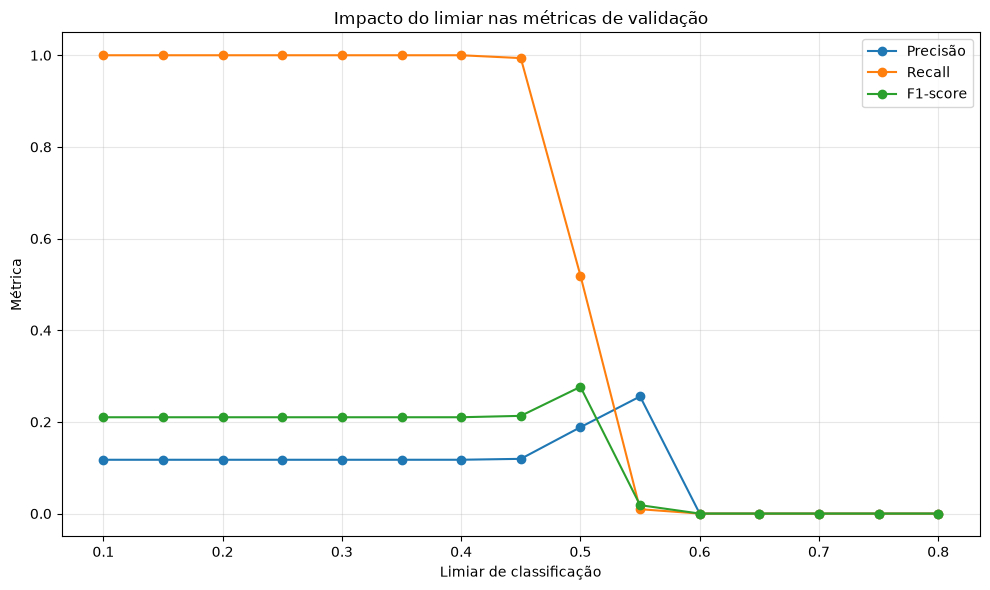

In [87]:

diretorio_imagens = (
    Path.cwd().parent.parent
    / "images"
    / "avaliacao_modelos"
)

diretorio_imagens.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))

plt.plot(
    tabela_limiares["limiar"],
    tabela_limiares["precision"],
    marker="o",
    label="Precisão",
)

plt.plot(
    tabela_limiares["limiar"],
    tabela_limiares["recall"],
    marker="o",
    label="Recall",
)

plt.plot(
    tabela_limiares["limiar"],
    tabela_limiares["f1"],
    marker="o",
    label="F1-score",
)

plt.xlabel("Limiar de classificação")
plt.ylabel("Métrica")
plt.title("Impacto do limiar nas métricas de validação")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    diretorio_imagens / "impacto_limiar_metricas_validacao.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Conclusão da Etapa 5 — Treinamento e avaliação dos modelos

Nesta etapa, foram implementados e avaliados três algoritmos de aprendizado supervisionado para a classificação de pedidos com risco de atraso nas entregas: Regressão Logística, Random Forest e Gradient Boosting. Para cada algoritmo, foram testadas seis combinações de hiperparâmetros, totalizando **18 experimentos**. Os modelos foram treinados utilizando o conjunto de treinamento e avaliados no conjunto de validação, considerando as métricas de acurácia, precisão, recall, F1-score e ROC-AUC, além dos tempos de treinamento e predição.

O conjunto de dados utilizado na modelagem possui 24 features, sendo 17 numéricas e 7 categóricas. O processo de treinamento considerou o pré-processamento adequado a cada algoritmo, incluindo imputação de valores ausentes, padronização das variáveis numéricas quando aplicável e codificação das variáveis categóricas. Também foram avaliadas configurações com ponderação de classes, buscando melhorar a identificação dos pedidos atrasados, que representam a classe minoritária.

Os resultados demonstraram que a **acurácia, isoladamente, não é suficiente para avaliar o desempenho dos modelos** neste problema. Algumas configurações de Regressão Logística, Random Forest e Gradient Boosting alcançaram acurácia próxima de 88%, mas apresentaram recall e F1-score iguais ou próximos de zero. Esse comportamento indica que os modelos tiveram dificuldade para identificar pedidos atrasados e, em determinadas configurações, classificaram praticamente todos os pedidos como não atrasados. Portanto, métricas como recall, F1-score e ROC-AUC foram fundamentais para comparar os experimentos.

A Regressão Logística apresentou resultados distintos conforme os hiperparâmetros utilizados. As configurações com `class_weight="balanced"` alcançaram recalls superiores às configurações sem ponderação de classes. O maior recall do algoritmo foi de **80,02%**, obtido com `C=0.01` e `class_weight="balanced"`, embora com precisão de 12,92% e F1-score de 0,2225. O maior F1-score foi de **0,2357**, obtido com `C=1.0` e `class_weight="balanced"`. Esses resultados demonstram que a ponderação de classes favoreceu a identificação de pedidos atrasados, embora com uma quantidade elevada de falsos positivos.

O Random Forest apresentou o melhor desempenho geral entre os algoritmos avaliados. Sua melhor configuração foi obtida no Experimento 4, com `n_estimators=100`, `max_depth=10` e `class_weight="balanced"`. Esse modelo alcançou **F1-score de 0,2766, ROC-AUC de 0,6527, precisão de 18,85% e recall de 51,93%**. Embora não tenha apresentado o maior recall entre todos os experimentos, obteve o maior F1-score e o maior ROC-AUC da comparação, indicando um equilíbrio mais favorável entre precisão e recall e uma capacidade superior de discriminação entre as classes. Além disso, seu tempo de treinamento foi de aproximadamente 5,13 segundos, consideravelmente inferior ao observado nos experimentos de Gradient Boosting.

O Gradient Boosting apresentou desempenho inferior na identificação dos pedidos atrasados. Sua melhor configuração foi obtida com `n_estimators=200` e `learning_rate=0.1`, alcançando F1-score de 0,0275, ROC-AUC de 0,6080, precisão de 17,73% e recall de apenas 1,49%. Além do baixo desempenho na identificação da classe minoritária, essa configuração apresentou o maior tempo de treinamento entre os 18 experimentos, aproximadamente 185,88 segundos. Dessa forma, o aumento da quantidade de árvores não proporcionou uma melhoria suficiente para compensar o custo computacional observado.

Após a comparação dos resultados, o **Random Forest com `n_estimators=100`, `max_depth=10` e `class_weight="balanced"` foi selecionado como principal candidato para as próximas avaliações**. A escolha foi baseada principalmente no maior F1-score e ROC-AUC entre as configurações testadas, além do tempo de treinamento relativamente baixo. Essa seleção representa o melhor resultado obtido nesta etapa, mas não constitui ainda uma validação definitiva do modelo para uso em produção.

Também foi realizada uma análise do impacto dos limiares de classificação utilizando as probabilidades previstas pelo Random Forest no conjunto de validação. Foram avaliados limiares entre 0,10 e 0,80. Entre os valores testados, o limiar de **0,50 apresentou o maior F1-score, de 0,2766**, com precisão de 18,85% e recall de 51,93%, classificando 6.648 pedidos como atrasados. Ao reduzir o limiar para 0,45, o recall aumentou para 99,38%, mas a precisão caiu para 11,94% e o F1-score para 0,2132. Com limiares entre 0,10 e 0,35, o recall chegou a 100%, porém todos os 20.550 pedidos do conjunto de validação foram classificados como atrasados. Esses resultados demonstram que a escolha do limiar influencia diretamente a quantidade de pedidos sinalizados e o equilíbrio entre a identificação de atrasos e a ocorrência de falsos positivos.

Dessa forma, o limiar de 0,50 foi mantido como referência inicial, por ter apresentado o maior F1-score entre os valores avaliados. Entretanto, a definição do limiar definitivo deverá considerar também os custos associados aos falsos positivos e aos falsos negativos, conforme os objetivos de negócio do projeto.

Conclui-se que a Etapa 5 cumpriu seu objetivo de treinar e comparar diferentes configurações de modelos de classificação para a previsão de risco de atraso nas entregas. O Random Forest apresentou os resultados mais promissores entre os experimentos realizados, enquanto a Regressão Logística permaneceu como uma referência relevante para comparação e o Gradient Boosting apresentou maior custo computacional sem ganhos proporcionais de desempenho.

Na próxima etapa, os resultados serão aprofundados por meio da comparação das métricas e da análise dos custos associados aos erros de classificação. O conjunto de teste permanecerá reservado para a Etapa 7, quando será realizada a avaliação final do modelo selecionado, sem utilizá-lo para orientar as decisões tomadas durante esta etapa.